# Advanced Algorithms: Coding Interview Workbook

> **Prerequisite:** the [DSA series](../dsa/01_complexity_analysis_and_recursion.ipynb) (`dsa/01`–`dsa/11`). Every pattern here was taught there; this notebook is for **practice**, not first contact.
>
> **Who is this for:** anyone preparing for a technical interview (software, ML or AI engineer), or a university student revising for an algorithms exam who wants many solved and **tested** problems in one place.
>
> **What you will learn:**
> - A repeatable **7-step method**: clarify → examples → brute force → optimise → code → test → analyse, shown end to end on 2 problems
> - **45 problems** grouped into **15 patterns** (two pointers, sliding window, prefix sums, hashing, monotonic stack, binary search on the answer, heaps/top-k, intervals, BFS/DFS on grids, topological sort, union-find, DP, backtracking, tries, bit tricks). Each one has a statement, a hidden hint, a reference solution, a hidden complexity analysis, fixed `assert` tests **and** random tests against a brute-force oracle
> - A **timing harness** that checks a claimed complexity by fitting the slope of a log-log plot
> - **Python interview idioms**: `collections`, `heapq`, `bisect`, `functools.cache`, recursion limits, and classic traps
> - **ML-flavoured coding questions**: k-means, ROC AUC, IoU and NMS, top-k / top-p sampling, a BPE tokenizer, an LRU cache for embeddings
> - A **4-week practice schedule** and a **self-assessment table**
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [`dsa/01` complexity](../dsa/01_complexity_analysis_and_recursion.ipynb); ideally the rest of the DSA series ([`dsa/09` DP](../dsa/09_dynamic_programming.ipynb), [`dsa/10` backtracking](../dsa/10_backtracking.ipynb)).
>
> **Time needed:** 1 hour to read; the problems are meant to be spread over the 4-week plan in section 21.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

**How to use it.** For each problem: read the statement, close the notebook for 20–30 minutes and solve it on paper or in a blank cell, open the hint only if stuck, and only then read the reference solution. Re-run the tests on **your** function by passing it to `random_check`.

## Explained simply

A coding interview gives you a small puzzle, such as "find two numbers in this list that add up to 10", and watches how you solve it. Nobody expects you to have memorised thousands of puzzles. What helps is noticing that most puzzles are **variations of about 15 patterns**, the same way most recipes are variations of a few cooking methods (boil, fry, bake). Once you can say "this smells like a sliding window", half the work is done. The other half is a calm routine: ask questions, try a slow but obviously correct answer first, then make it fast, then **test** it. Testing a fast answer against the slow one on hundreds of random inputs is the single best habit in this notebook, and it is also how real engineers check tricky code.

**Everyday analogies.**
- **Two pointers** is like two people searching a sorted bookshelf from both ends and walking towards each other.
- **Sliding window** is like a train window: as the train moves, one new house appears on the right and one disappears on the left, so you never have to look at the whole street again.
- **Binary search** is the "guess my number between 1 and 100" game: "higher" or "lower" halves the range each time, so 7 guesses always suffice.

**A tiny example.** Prices of a toy on 6 days: 7, 1, 5, 3, 6, 4. When should you buy and sell once to earn the most? The slow way checks all 15 buy/sell pairs. The fast way walks once through the days remembering the cheapest price so far (7, then 1) and the best profit so far: on day 5 the price is 6, so the profit is 6 − 1 = **5**, the answer. The fast way looks at each day once instead of comparing every pair.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Pattern | a reusable trick that solves a family of puzzles | "top-k" = keep the k best search results in a RAG system |
| Brute force | try everything; slow but surely correct | the "oracle" used to test fast code |
| Complexity | how the running time grows as the input grows | why a recommender uses a heap, not a full sort |

## 0. Setup

> 💬 **In plain English:** load the tools and a tiny test harness that compares a fast solution with a slow, obviously-correct one.

In [1]:
import bisect, copy, functools, heapq, itertools, math, random, re, statistics, sys, time, timeit, zlib
from collections import Counter, OrderedDict, defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy import ndimage

random.seed(42); np.random.seed(42)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)


def random_check(solution, oracle, make_input, trials=300, seed=0, compare=None):
    """Run `solution` and a brute-force `oracle` on `trials` random inputs from make_input(rng).
    `compare(got, want, args)` decides equality when several answers are valid (default: ==).
    Returns the number of trials; raises AssertionError with the failing input otherwise."""
    rng = random.Random(seed)
    for t in range(trials):
        args = make_input(rng)
        got = solution(*copy.deepcopy(args))      # deep copies: a solution must not see the oracle's mutations
        want = oracle(*copy.deepcopy(args))
        ok = compare(got, want, args) if compare else got == want
        if not ok:
            raise AssertionError(f"trial {t}: input={args!r}\n got ={got!r}\n want={want!r}")
    return trials

RESULTS = []                                       # (problem, fixed tests, random tests) for the summary
def report(name, n_fixed, n_random):
    RESULTS.append((name, n_fixed, n_random))
    print(f"✅ {name}: {n_fixed} fixed + {n_random} random tests passed")

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| networkx", nx.__version__)

PATTERN_COUNTS = [('Two pointers', 3), ('Sliding window', 3), ('Prefix sums', 2), ('Hashing', 3), ('Stack and monotonic stack', 3), ('Binary search (on an index and on the answer)', 4), ('Heap and top-k', 4), ('Intervals', 3), ('BFS / DFS on grids', 3), ('Topological sort', 1), ('Union-find (disjoint set union)', 2), ('Dynamic programming (1-D, 2-D, knapsack, LIS, edit distance)', 7), ('Backtracking', 4), ('Tries', 1), ('Bit manipulation', 2)]   # (pattern, number of problems), used in section 21

Python 3.12.3 | numpy 2.4.6 | networkx 3.7


## 1. The method: clarify → examples → brute force → optimise → code → test → analyse

> 💬 **In plain English:** a 7-step routine for any interview problem, shown on two problems from start to finish.

Interviewers grade the **process** as much as the answer. A widely used rubric scores communication, problem solving, coding and verification. This routine hits all four.

| Step | What you do | What you say out loud |
|---|---|---|
| 1. **Clarify** | Inputs, sizes, types, edge cases (empty, duplicates, negatives), output format | "Can the list be empty? Are values bounded? Do you want indices or values?" |
| 2. **Examples** | Work 1–2 small examples by hand, including an edge case | "For `[7, 1, 5]` I expect 4." |
| 3. **Brute force** | State the obvious correct solution and its complexity | "Trying all pairs is $O(n^2)$; that is my baseline." |
| 4. **Optimise** | Find the bottleneck; ask which pattern removes it | "The inner loop only needs the minimum so far, so I can keep it in a variable." |
| 5. **Code** | Clean, named variables, small helpers | Narrate invariants while typing. |
| 6. **Test** | Walk your examples through the code; then edge cases | "Empty list returns 0 because the loop never runs." |
| 7. **Analyse** | Time and space, best/worst case | "$O(n)$ time, $O(1)$ space." |

🎓 **Interview tip:** always say the brute force first, even if you see the trick immediately. It proves you understand the problem, gives you a fallback, and in this notebook becomes the **test oracle**.

### Worked example A: best time to buy and sell a stock (one transaction)

**Problem.** `prices[i]` is a stock price on day `i`. Buy on one day and sell on a **later** day; return the maximum profit, or `0` if no profit is possible.

**1. Clarify.** Can I buy and sell on the same day? (Yes, profit 0, so the answer is never negative.) Empty list? (Return 0.) Size? (Up to $10^5$, so $O(n^2)$ = $10^{10}$ operations is too slow.)

**2. Examples.** `[7, 1, 5, 3, 6, 4]` → buy at 1, sell at 6 → **5**. `[7, 6, 4, 3, 1]` → prices only fall → **0**.

**3. Brute force.** Try every pair `i < j`: $O(n^2)$ time, $O(1)$ space.

**4. Optimise.** For a fixed selling day `j`, the best buying day is simply the **minimum price before `j`**. So keep a running minimum: one pass, $O(n)$.

| day | price | lowest so far | profit if sold today | best |
|---|---|---|---|---|
| 0 | 7 | 7 | 0 | 0 |
| 1 | 1 | 1 | 0 | 0 |
| 2 | 5 | 1 | 4 | 4 |
| 3 | 3 | 1 | 2 | 4 |
| 4 | 6 | 1 | 5 | **5** |
| 5 | 4 | 1 | 3 | 5 |

In [2]:
# Steps 3 and 5: brute force (the oracle) and the optimised solution
def max_profit_brute(prices):
    best = 0
    for i in range(len(prices)):              # buy day
        for j in range(i + 1, len(prices)):   # sell day, strictly later
            best = max(best, prices[j] - prices[i])
    return best

def max_profit(prices):
    best, lowest = 0, math.inf
    for p in prices:
        lowest = min(lowest, p)               # cheapest buying price seen so far
        best = max(best, p - lowest)          # profit if we sell today
    return best

# Step 6: test. First the hand examples and edge cases ...
assert max_profit([7, 1, 5, 3, 6, 4]) == 5
assert max_profit([7, 6, 4, 3, 1]) == 0
assert max_profit([]) == 0 and max_profit([3]) == 0
# ... then 500 random inputs against the brute force
n = random_check(max_profit, max_profit_brute,
                 lambda r: ([r.randint(0, 20) for _ in range(r.randint(0, 12))],), trials=500)
report("Worked A: best time to buy and sell", 4, n)

✅ Worked A: best time to buy and sell: 4 fixed + 500 random tests passed


**What just happened?** The fast solution agreed with the brute force on 500 random lists (and on the 4 hand-picked cases). **7. Analyse:** $O(n)$ time (one pass), $O(1)$ space (two variables). This is LeetCode #121; the same "best so far" idea is **Kadane's algorithm** for the maximum subarray sum.

### Worked example B: longest substring without repeating characters

**1. Clarify.** Substring = contiguous. Characters: any Unicode. Empty string → 0.

**2. Examples.** `"abcabcbb"` → `"abc"` → **3**. `"bbbbb"` → **1**. `"pwwkew"` → `"wke"` → **3** (`"pwke"` is a subsequence, not a substring).

**3. Brute force.** Check every substring `s[i:j]` for duplicates with a set: $O(n^3)$ (or $O(n^2)$ if you extend each start until the first repeat).

**4. Optimise.** If `s[i:j]` has no repeats, neither has any substring inside it, so the property is **monotone**: this is a **sliding window**. Move `right` forward; when `s[right]` was already seen inside the window, jump `left` to just after its last occurrence.

```
s = a b c a b c b b
    L   R              window "abc", length 3
      L   R            'a' repeats: left jumps past the old 'a'  -> "bca"
```

In [3]:
def longest_unique_brute(s):
    return max((j - i for i in range(len(s)) for j in range(i + 1, len(s) + 1) if len(set(s[i:j])) == j - i), default=0)

def longest_unique(s):
    last = {}                                  # char -> index of its latest occurrence
    left = best = 0
    for right, ch in enumerate(s):
        if ch in last and last[ch] >= left:    # repeat inside the current window
            left = last[ch] + 1                # jump past it (left never moves backwards)
        last[ch] = right
        best = max(best, right - left + 1)
    return best

assert longest_unique("abcabcbb") == 3 and longest_unique("bbbbb") == 1
assert longest_unique("pwwkew") == 3 and longest_unique("") == 0 and longest_unique("abba") == 2
n = random_check(longest_unique, longest_unique_brute,
                 lambda r: ("".join(r.choice("abcd") for _ in range(r.randint(0, 12))),), trials=500)
report("Worked B: longest substring without repeats", 5, n)

✅ Worked B: longest substring without repeats: 5 fixed + 500 random tests passed


**What just happened?** The test `"abba"` is the classic trap: when the second `a` arrives, its last occurrence (index 0) is **outside** the window, so `left` must not move back. The condition `last[ch] >= left` handles it, and the random tests would have caught the bug if it were missing. **Analyse:** $O(n)$ time, since `right` moves $n$ times and `left` only moves forward; $O(\min(n, \sigma))$ space for the dictionary ($\sigma$ = alphabet size). LeetCode #3.

⚠️ **Common mistake:** "testing" only on the examples from the statement. Interviewers deliberately pick examples that hide the edge cases. Always add: empty input, one element, all equal, already sorted, negative numbers, and the largest allowed size.

## 2. Pattern map: from the wording to the technique

> 💬 **In plain English:** a one-page map from 'what the question says' to 'which pattern to try'.

| If the problem says ... | Try | Typical complexity |
|---|---|---|
| sorted array, pair/triplet with a target sum, compare from both ends | two pointers | $O(n)$ after sorting |
| longest/shortest contiguous subarray or substring with a monotone condition | sliding window | $O(n)$ |
| many range-sum queries; count subarrays with sum $k$ (negatives allowed) | prefix sums + hash map | $O(n)$ |
| "seen before?", complements, grouping by a canonical form | hash map / set | $O(n)$ expected |
| brackets, next greater/smaller element, histogram, "undo" | stack / monotonic stack | $O(n)$ |
| sorted data, or "minimum X such that a monotone check passes" | binary search (on index or on answer) | $O(\log n)$ or $O(n \log M)$ |
| k largest/smallest/closest, merge k sorted, running median | heap | $O(n \log k)$ |
| meetings, ranges, overlaps | sort + sweep, or greedy by end | $O(n \log n)$ |
| grid/maze, connected regions, fewest steps, spreading | BFS / DFS | $O(RC)$ |
| prerequisites, build order, cycle in a directed graph | topological sort | $O(V + E)$ |
| dynamic connectivity, merging groups, cycle in an undirected graph | union-find | $O(\alpha(n))$ per op |
| count ways / min cost / longest, with overlapping subproblems | dynamic programming | states × transitions |
| "all" subsets / permutations / placements | backtracking | output-sensitive, exponential |
| many prefix queries over words | trie | $O(L)$ per query |
| "no extra memory", pairs cancel, small sets as masks | bit manipulation | $O(n)$ / $O(2^n)$ |

The workbook sections that follow, with the number of problems in each:

| Section | Pattern | Problems |
|---|---|---|
| 3 | Two pointers | 3 |
| 4 | Sliding window | 3 |
| 5 | Prefix sums | 2 |
| 6 | Hashing | 3 |
| 7 | Stack and monotonic stack | 3 |
| 8 | Binary search (on an index and on the answer) | 4 |
| 9 | Heap and top-k | 4 |
| 10 | Intervals | 3 |
| 11 | BFS / DFS on grids | 3 |
| 12 | Topological sort | 1 |
| 13 | Union-find (disjoint set union) | 2 |
| 14 | Dynamic programming (1-D, 2-D, knapsack, LIS, edit distance) | 7 |
| 15 | Backtracking | 4 |
| 16 | Tries | 1 |
| 17 | Bit manipulation | 2 |

## 3. Two pointers

**Signal in the statement:** the input is **sorted** (or you may sort it), and you look for a **pair/triplet** with some property, or you compare elements from both ends.

**Idea:** keep two indices, usually one at each end. Each step moves one pointer, and the sortedness tells you which one can be moved safely. Every step throws away a whole row of candidate pairs, so $O(n^2)$ pairs are examined in $O(n)$ steps.

```
a = [1, 3, 4, 6, 9]   target 10
     i           j     1 + 9 = 10  found
```

### Problem 1: Two Sum II (sorted input) *(LeetCode #167)*

Given a **sorted** list `a` and a `target`, return indices `(i, j)` with `i < j` and `a[i] + a[j] == target`, or `None` if no pair exists. Example: `a = [1, 3, 4, 6, 9]`, `target = 10` → `(0, 4)` (or `(2, 3)`; any valid pair is accepted).

<details><summary>💡 Hint</summary>

If `a[i] + a[j]` is too small, can **any** pair that uses `a[i]` with a smaller `a[j]` work? So which pointer must move?

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time: each loop step moves `i` right or `j` left, so there are at most $n-1$ steps. $O(1)$ extra space.

</details>

In [4]:
def two_sum_sorted(a, target):
    """Two pointers on a sorted list: O(n) time, O(1) space."""
    i, j = 0, len(a) - 1                 # one pointer at each end
    while i < j:
        s = a[i] + a[j]
        if s == target:
            return (i, j)
        if s < target:                   # too small: a[i] cannot pair with anything to its right
            i += 1
        else:                            # too big: a[j] cannot pair with anything to its left
            j -= 1
    return None

def two_sum_brute(a, target):            # oracle: try every pair, O(n^2)
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            if a[i] + a[j] == target:
                return (i, j)
    return None

def valid_pair(got, want, args):         # several answers may be correct, so check validity
    a, target = args
    if want is None:
        return got is None
    return got is not None and got[0] < got[1] and a[got[0]] + a[got[1]] == target

assert valid_pair(two_sum_sorted([1, 3, 4, 6, 9], 10), (0, 4), ([1, 3, 4, 6, 9], 10))
assert two_sum_sorted([1, 2], 10) is None and two_sum_sorted([], 0) is None
n = random_check(two_sum_sorted, two_sum_brute,
                 lambda r: (sorted(r.randint(-20, 20) for _ in range(r.randint(0, 12))), r.randint(-40, 40)),
                 compare=valid_pair)
report("Two Sum II", 3, n)

✅ Two Sum II: 3 fixed + 300 random tests passed


### Problem 2: Container with most water *(LeetCode #11)*

`h[i]` is the height of a vertical line at position `i`. Choose two lines that, with the x-axis, hold the most water: maximise `min(h[i], h[j]) * (j - i)`. Example: `[1, 8, 6, 2, 5, 4, 8, 3, 7]` → `49` (lines at 1 and 8).

<details><summary>💡 Hint</summary>

Start with the widest container. Moving the **taller** line inwards can never help (width shrinks, height is still capped by the shorter line). So always move the shorter one.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time (one inward step per iteration), $O(1)$ space. Correctness: the discarded line is the shorter one, and every container it could still form is narrower and no taller, so none beats the current one.

</details>

In [5]:
def max_area(h):
    """Two pointers from both ends; always move the shorter line."""
    i, j, best = 0, len(h) - 1, 0
    while i < j:
        best = max(best, min(h[i], h[j]) * (j - i))   # water held by lines i and j
        if h[i] < h[j]:
            i += 1                                   # the shorter line is the bottleneck
        else:
            j -= 1
    return best

def max_area_brute(h):
    return max((min(h[i], h[j]) * (j - i) for i in range(len(h)) for j in range(i + 1, len(h))), default=0)

assert max_area([1, 8, 6, 2, 5, 4, 8, 3, 7]) == 49 and max_area([1, 1]) == 1 and max_area([5]) == 0
n = random_check(max_area, max_area_brute, lambda r: ([r.randint(0, 10) for _ in range(r.randint(0, 12))],))
report("Container with most water", 3, n)

✅ Container with most water: 3 fixed + 300 random tests passed


### Problem 3: 3Sum (all unique triplets summing to zero) *(LeetCode #15)*

Return all **unique** triplets `(x, y, z)` (as sorted tuples, in sorted order) from `nums` with `x + y + z == 0`. Example: `[-1, 0, 1, 2, -1, -4]` → `[(-1, -1, 2), (-1, 0, 1)]`.

<details><summary>💡 Hint</summary>

Sort first. Fix the smallest element `nums[i]`, then the problem becomes Two Sum II on the rest. Skip equal neighbours to avoid duplicate triplets.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n^2)$ time: sorting is $O(n \log n)$, then $n$ two-pointer passes of $O(n)$ each. $O(1)$ extra space besides the output (Python's sort uses $O(n)$). $O(n^2)$ is believed optimal for 3Sum in general (the "3SUM conjecture", up to small log factors).

</details>

In [6]:
def three_sum(nums):
    nums = sorted(nums)
    out = []
    for i in range(len(nums) - 2):
        if i > 0 and nums[i] == nums[i - 1]:
            continue                            # same smallest element as before: skip duplicates
        lo, hi = i + 1, len(nums) - 1
        while lo < hi:
            s = nums[i] + nums[lo] + nums[hi]
            if s < 0:
                lo += 1
            elif s > 0:
                hi -= 1
            else:
                out.append((nums[i], nums[lo], nums[hi]))
                lo += 1
                while lo < hi and nums[lo] == nums[lo - 1]:
                    lo += 1                     # skip duplicate middle elements
    return out

def three_sum_brute(nums):
    return sorted({tuple(sorted(c)) for c in itertools.combinations(nums, 3) if sum(c) == 0})

assert three_sum([-1, 0, 1, 2, -1, -4]) == [(-1, -1, 2), (-1, 0, 1)]
assert three_sum([0, 0, 0, 0]) == [(0, 0, 0)] and three_sum([1, 2]) == []
n = random_check(three_sum, three_sum_brute, lambda r: ([r.randint(-6, 6) for _ in range(r.randint(0, 10))],))
report("3Sum", 3, n)

✅ 3Sum: 3 fixed + 300 random tests passed


## 4. Sliding window

**Signal:** "longest/shortest **contiguous** subarray or substring such that ...", and the condition is **monotone**: if a window is valid, so is every smaller (or larger) window inside it.

**Idea:** grow the window on the right; while it breaks the rule, shrink it from the left. Each index enters and leaves the window at most once, so the total work is $O(n)$, even though there is a loop inside a loop. (Worked example B in section 1 was a sliding window.)

```
target sum >= 7, nums = [2, 3, 1, 2, 4, 3]
[2 3 1 2] 4 3      sum 8 >= 7, length 4, shrink
 2[3 1 2 4]3       sum 10, length 4, shrink ...
 2 3 1 2[4 3]      sum 7, length 2  <- best
```

### Problem 4: Minimum size subarray sum *(LeetCode #209)*

Given **positive** integers `nums` and `target`, return the length of the shortest contiguous subarray with sum `>= target`, or `0` if none. Example: `target = 7, nums = [2, 3, 1, 2, 4, 3]` → `2` (`[4, 3]`).

<details><summary>💡 Hint</summary>

With positive numbers, adding an element only increases the sum and removing one only decreases it. That monotonicity is exactly what a sliding window needs.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time: `right` moves $n$ times and `left` moves at most $n$ times in total (amortised argument). $O(1)$ space. ⚠️ With negative numbers the window idea breaks (shrinking could increase the sum); use prefix sums plus a monotonic deque instead.

</details>

In [7]:
def min_subarray_len(target, nums):
    left, total, best = 0, 0, math.inf
    for right, x in enumerate(nums):
        total += x                            # grow the window to include nums[right]
        while total >= target:                # valid: record it, then try to shrink
            best = min(best, right - left + 1)
            total -= nums[left]
            left += 1
    return 0 if best == math.inf else best

def min_subarray_len_brute(target, nums):
    best = math.inf
    for i in range(len(nums)):
        for j in range(i, len(nums)):
            if sum(nums[i:j + 1]) >= target:
                best = min(best, j - i + 1)
    return 0 if best == math.inf else best

assert min_subarray_len(7, [2, 3, 1, 2, 4, 3]) == 2 and min_subarray_len(100, [1, 2]) == 0
n = random_check(min_subarray_len, min_subarray_len_brute,
                 lambda r: (r.randint(1, 30), [r.randint(1, 9) for _ in range(r.randint(0, 10))]))
report("Minimum size subarray sum", 2, n)

✅ Minimum size subarray sum: 2 fixed + 300 random tests passed


### Problem 5: Minimum window substring *(LeetCode #76)*

Return the shortest substring of `s` that contains every character of `t` (with multiplicity), or `""`. If several have the same length, return the leftmost. Example: `s = "ADOBECODEBANC", t = "ABC"` → `"BANC"`.

<details><summary>💡 Hint</summary>

Keep a counter `need` of characters still missing and a number `missing`. Expand right until `missing == 0`, then shrink left while it stays 0.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(|s| + |t|)$ time: each index of `s` enters and leaves the window once, and counter updates are $O(1)$. $O(\sigma)$ space for the counters ($\sigma$ = alphabet size).

</details>

In [8]:
def min_window(s, t):
    need = Counter(t)                 # how many of each char we still need (can go negative = surplus)
    missing = len(t)                  # total chars still missing
    left, best = 0, (math.inf, 0, 0)  # (length, start, end)
    for right, ch in enumerate(s):
        if need[ch] > 0:
            missing -= 1
        need[ch] -= 1
        while missing == 0:           # window s[left:right+1] is valid: shrink it
            if right - left + 1 < best[0]:
                best = (right - left + 1, left, right + 1)
            need[s[left]] += 1
            if need[s[left]] > 0:     # we just removed a needed char
                missing += 1
            left += 1
    return "" if best[0] == math.inf else s[best[1]:best[2]]

def min_window_brute(s, t):
    need, best = Counter(t), ""
    for i in range(len(s)):
        for j in range(i + 1, len(s) + 1):
            if not need - Counter(s[i:j]) and (best == "" or j - i < len(best)):
                best = s[i:j]
    return best

assert min_window("ADOBECODEBANC", "ABC") == "BANC" and min_window("a", "aa") == ""
n = random_check(min_window, min_window_brute,
                 lambda r: ("".join(r.choice("abc") for _ in range(r.randint(0, 12))),
                            "".join(r.choice("abc") for _ in range(r.randint(1, 3)))))
report("Minimum window substring", 2, n)

✅ Minimum window substring: 2 fixed + 300 random tests passed


### Problem 6: Sliding window maximum (monotonic deque) *(LeetCode #239)*

Return the maximum of every window of size `k`. Example: `nums = [1, 3, -1, -3, 5, 3, 6, 7], k = 3` → `[3, 3, 5, 5, 6, 7]`.

<details><summary>💡 Hint</summary>

Keep a deque of **indices** whose values are decreasing. A new value evicts all smaller values from the back (they can never be a maximum again). The front is the current maximum; drop it when it leaves the window.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time: each index is pushed and popped at most once. $O(k)$ space. A heap would give $O(n \log n)$; this is the standard "monotonic queue" trick.

</details>

In [9]:
def max_sliding_window(nums, k):
    dq, out = deque(), []                 # dq holds indices, values decreasing from front to back
    for i, x in enumerate(nums):
        while dq and nums[dq[-1]] <= x:   # smaller values behind x can never be a max again
            dq.pop()
        dq.append(i)
        if dq[0] <= i - k:                # front index slid out of the window
            dq.popleft()
        if i >= k - 1:
            out.append(nums[dq[0]])
    return out

def max_sliding_window_brute(nums, k):
    return [max(nums[i:i + k]) for i in range(len(nums) - k + 1)]

assert max_sliding_window([1, 3, -1, -3, 5, 3, 6, 7], 3) == [3, 3, 5, 5, 6, 7]
def gen(r):
    n = r.randint(1, 12)
    return [r.randint(-5, 5) for _ in range(n)], r.randint(1, n)
n = random_check(max_sliding_window, max_sliding_window_brute, gen)
report("Sliding window maximum", 1, n)

✅ Sliding window maximum: 1 fixed + 300 random tests passed


## 5. Prefix sums

**Signal:** many questions about **sums of ranges**, or "count subarrays whose sum is ...", possibly with **negative** numbers.

**Idea:** $P[i] = a_0 + \dots + a_{i-1}$, so the sum of `a[l:r]` is $P[r] - P[l]$ in $O(1)$. "Subarray sum equals $k$" becomes "how many earlier prefixes equal $P[r] - k$?", answered by a hash map.

| i | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| a | 1 | 2 | 3 | |
| P | 0 | 1 | 3 | 6 |

Sum of `a[1:3]` = $P[3] - P[1] = 6 - 1 = 5$ = 2 + 3.

### Problem 7: Subarray sum equals k (count) *(LeetCode #560)*

Count contiguous subarrays of `nums` (which may contain negatives) whose sum is exactly `k`. Example: `nums = [1, 1, 1], k = 2` → `2`.

<details><summary>💡 Hint</summary>

A subarray ending at `r` has sum `k` exactly when some earlier prefix sum equals `prefix_r - k`. Count prefix sums in a dictionary as you go. Start with `{0: 1}` for the empty prefix.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ expected time (one hash lookup and update per element), $O(n)$ space for the counts. Sliding window does **not** work here because of negative numbers.

</details>

In [10]:
def subarray_sum_count(nums, k):
    seen = defaultdict(int)
    seen[0] = 1                    # the empty prefix
    prefix = count = 0
    for x in nums:
        prefix += x
        count += seen[prefix - k]  # earlier prefixes p with prefix - p == k
        seen[prefix] += 1
    return count

def subarray_sum_count_brute(nums, k):
    return sum(1 for i in range(len(nums)) for j in range(i + 1, len(nums) + 1) if sum(nums[i:j]) == k)

assert subarray_sum_count([1, 1, 1], 2) == 2 and subarray_sum_count([1, -1, 0], 0) == 3
n = random_check(subarray_sum_count, subarray_sum_count_brute,
                 lambda r: ([r.randint(-3, 3) for _ in range(r.randint(0, 10))], r.randint(-3, 3)))
report("Subarray sum equals k", 2, n)

✅ Subarray sum equals k: 2 fixed + 300 random tests passed


### Problem 8: Product of array except self (no division) *(LeetCode #238)*

Return `out` where `out[i]` is the product of all elements except `nums[i]`, **without using division** (zeros make division unsafe). Example: `[1, 2, 3, 4]` → `[24, 12, 8, 6]`.

<details><summary>💡 Hint</summary>

`out[i]` = (product of everything left of `i`) × (product of everything right of `i`). Two passes: prefix products, then suffix products.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time (two passes), $O(1)$ extra space if the output array does not count.

</details>

In [11]:
def product_except_self(nums):
    n = len(nums)
    out = [1] * n
    left = 1
    for i in range(n):            # out[i] = product of nums[:i]
        out[i] = left
        left *= nums[i]
    right = 1
    for i in range(n - 1, -1, -1):  # multiply in product of nums[i+1:]
        out[i] *= right
        right *= nums[i]
    return out

def product_except_self_brute(nums):
    return [math.prod(nums[:i] + nums[i + 1:]) for i in range(len(nums))]

assert product_except_self([1, 2, 3, 4]) == [24, 12, 8, 6] and product_except_self([0, 2, 0]) == [0, 0, 0]
n = random_check(product_except_self, product_except_self_brute,
                 lambda r: ([r.randint(-3, 3) for _ in range(r.randint(1, 8))],))
report("Product except self", 2, n)

✅ Product except self: 2 fixed + 300 random tests passed


## 6. Hashing

**Signal:** "have I seen this before?", "group items that are equivalent", "find a complement", or you need $O(1)$ membership.

**Idea:** a `dict`/`set` turns an $O(n)$ search into an $O(1)$ expected lookup, trading memory for time. The art is choosing the **key**: the complement `target - x`, a canonical form such as sorted letters, or a counter tuple.

### Problem 9: Two Sum (unsorted) *(LeetCode #1)*

Return indices `(i, j)`, `i < j`, with `nums[i] + nums[j] == target`, or `None`. The list is **not** sorted. Example: `[2, 7, 11, 15], target = 9` → `(0, 1)`.

<details><summary>💡 Hint</summary>

For each `x`, the partner you need is `target - x`. Have you seen it already?

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ expected time, $O(n)$ space. Sorting plus two pointers would be $O(n \log n)$ and would lose the original indices unless you sort (value, index) pairs.

</details>

In [12]:
def two_sum(nums, target):
    where = {}                          # value -> an index where it occurs
    for j, x in enumerate(nums):
        if target - x in where:
            return (where[target - x], j)
        where[x] = j
    return None

assert two_sum([2, 7, 11, 15], 9) == (0, 1) and two_sum([3, 3], 6) == (0, 1) and two_sum([1], 2) is None
n = random_check(two_sum, two_sum_brute,
                 lambda r: ([r.randint(-10, 10) for _ in range(r.randint(0, 10))], r.randint(-20, 20)),
                 compare=valid_pair)
report("Two Sum", 3, n)

✅ Two Sum: 3 fixed + 300 random tests passed


### Problem 10: Group anagrams *(LeetCode #49)*

Group words that are anagrams of each other. Example: `["eat", "tea", "tan", "ate", "nat", "bat"]` → `[["eat", "tea", "ate"], ["tan", "nat"], ["bat"]]` (any order).

<details><summary>💡 Hint</summary>

Two words are anagrams iff their sorted letters are equal. Use that (or a 26-count tuple) as the dictionary key.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \cdot L \log L)$ time with sorted keys ($L$ = word length), or $O(n L)$ with a letter-count key. $O(nL)$ space.

</details>

In [13]:
def group_anagrams(words):
    groups = defaultdict(list)
    for w in words:
        groups["".join(sorted(w))].append(w)   # canonical key: sorted letters
    return list(groups.values())

def group_anagrams_brute(words):                # O(n^2): compare with each group's first word
    groups = []
    for w in words:
        for g in groups:
            if Counter(g[0]) == Counter(w):
                g.append(w); break
        else:
            groups.append([w])
    return groups

canon = lambda groups: sorted(sorted(g) for g in groups)
assert canon(group_anagrams(["eat", "tea", "tan", "ate", "nat", "bat"])) == [["ate", "eat", "tea"], ["bat"], ["nat", "tan"]]
n = random_check(group_anagrams, group_anagrams_brute,
                 lambda r: (["".join(r.choice("abc") for _ in range(r.randint(0, 3))) for _ in range(r.randint(0, 8))],),
                 compare=lambda g, w, a: canon(g) == canon(w))
report("Group anagrams", 1, n)

✅ Group anagrams: 1 fixed + 300 random tests passed


### Problem 11: Longest consecutive sequence in O(n) *(LeetCode #128)*

Return the length of the longest run of consecutive integers (in any order) in `nums`. Example: `[100, 4, 200, 1, 3, 2]` → `4` (1, 2, 3, 4). Sorting gives $O(n \log n)$; do it in $O(n)$.

<details><summary>💡 Hint</summary>

Put everything in a set. Only start counting from `x` when `x - 1` is **not** in the set (so `x` begins a run).

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ expected time: each number is visited by the inner `while` at most once (only from the start of its run). $O(n)$ space.

</details>

In [14]:
def longest_consecutive(nums):
    s, best = set(nums), 0
    for x in s:
        if x - 1 not in s:              # x starts a run
            y = x
            while y + 1 in s:
                y += 1
            best = max(best, y - x + 1)
    return best

def longest_consecutive_brute(nums):
    xs, best, run = sorted(set(nums)), 0, 0
    for i, x in enumerate(xs):
        run = run + 1 if i and xs[i - 1] == x - 1 else 1
        best = max(best, run)
    return best

assert longest_consecutive([100, 4, 200, 1, 3, 2]) == 4 and longest_consecutive([]) == 0
n = random_check(longest_consecutive, longest_consecutive_brute,
                 lambda r: ([r.randint(-8, 8) for _ in range(r.randint(0, 12))],))
report("Longest consecutive sequence", 2, n)

✅ Longest consecutive sequence: 2 fixed + 300 random tests passed


## 7. Stack and monotonic stack

**Signal:** matching brackets, "undo", nested structure, or **"next greater/smaller element"**, spans and histograms.

**Idea:** a **monotonic stack** keeps elements in increasing (or decreasing) order. When a new element breaks the order, the popped elements have just found their "next greater" element. Each element is pushed and popped once, so the whole scan is $O(n)$.

```
temps:  73 74 75 71 69 72 76
stack after each step (indices of temps still waiting for a warmer day):
[0] -> [1] -> [2] -> [2,3] -> [2,3,4] -> [2,5] -> [6]
```

### Problem 12: Valid parentheses *(LeetCode #20)*

Is a string of `()[]{}` balanced? Example: `"([]{})"` → `True`, `"(]"` → `False`.

<details><summary>💡 Hint</summary>

Push openers. On a closer, the top of the stack must be its matching opener.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time, $O(n)$ space in the worst case (all openers).

</details>

In [15]:
def is_valid_parens(s):
    match = {")": "(", "]": "[", "}": "{"}
    stack = []
    for ch in s:
        if ch in match:
            if not stack or stack.pop() != match[ch]:
                return False
        else:
            stack.append(ch)
    return not stack                      # leftover openers are unmatched

def is_valid_parens_brute(s):             # repeatedly delete adjacent pairs: O(n^2)
    prev = None
    while prev != s:
        prev, s = s, s.replace("()", "").replace("[]", "").replace("{}", "")
    return s == ""

assert is_valid_parens("([]{})") and not is_valid_parens("(]") and not is_valid_parens("((")
n = random_check(is_valid_parens, is_valid_parens_brute,
                 lambda r: ("".join(r.choice("()[]{}") for _ in range(r.randint(0, 8))),), trials=1000)
report("Valid parentheses", 3, n)

✅ Valid parentheses: 3 fixed + 1000 random tests passed


### Problem 13: Daily temperatures (next greater element) *(LeetCode #739)*

For each day, how many days until a warmer temperature? `0` if never. Example: `[73, 74, 75, 71, 69, 72, 76, 73]` → `[1, 1, 4, 2, 1, 1, 0, 0]`.

<details><summary>💡 Hint</summary>

Keep a stack of indices with **decreasing** temperatures. A warmer day pops every colder day on the stack and answers them.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time (each index pushed and popped once), $O(n)$ space.

</details>

In [16]:
def daily_temperatures(t):
    out, stack = [0] * len(t), []         # stack: indices still waiting for a warmer day
    for i, x in enumerate(t):
        while stack and t[stack[-1]] < x:
            j = stack.pop()
            out[j] = i - j
        stack.append(i)
    return out

def daily_temperatures_brute(t):
    return [next((j - i for j in range(i + 1, len(t)) if t[j] > t[i]), 0) for i in range(len(t))]

assert daily_temperatures([73, 74, 75, 71, 69, 72, 76, 73]) == [1, 1, 4, 2, 1, 1, 0, 0]
n = random_check(daily_temperatures, daily_temperatures_brute,
                 lambda r: ([r.randint(30, 40) for _ in range(r.randint(0, 12))],))
report("Daily temperatures", 1, n)

✅ Daily temperatures: 1 fixed + 300 random tests passed


### Problem 14: Largest rectangle in a histogram *(LeetCode #84)*

Bars have width 1 and heights `h`. Return the area of the largest rectangle. Example: `[2, 1, 5, 6, 2, 3]` → `10` (heights 5 and 6, width 2).

<details><summary>💡 Hint</summary>

For each bar, the widest rectangle of exactly its height spans until the nearest **smaller** bar on each side. An increasing stack finds both at the moment a bar is popped.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time, $O(n)$ space. A sentinel height `0` at the end flushes the stack. This is also the core of "maximal rectangle of 1s in a binary matrix" ($O(rows \times cols)$).

</details>

In [17]:
def largest_rectangle(h):
    stack, best = [], 0                     # stack of indices with increasing heights
    for i, x in enumerate(h + [0]):         # sentinel 0 pops everything at the end
        while stack and h[stack[-1]] >= x:
            j = stack.pop()
            left = stack[-1] + 1 if stack else 0   # first index after the previous smaller bar
            best = max(best, h[j] * (i - left))
        stack.append(i)
    return best

def largest_rectangle_brute(h):
    best = 0
    for i in range(len(h)):
        low = math.inf
        for j in range(i, len(h)):
            low = min(low, h[j])
            best = max(best, low * (j - i + 1))
    return best

assert largest_rectangle([2, 1, 5, 6, 2, 3]) == 10 and largest_rectangle([]) == 0
n = random_check(largest_rectangle, largest_rectangle_brute,
                 lambda r: ([r.randint(0, 6) for _ in range(r.randint(0, 12))],))
report("Largest rectangle in histogram", 2, n)

✅ Largest rectangle in histogram: 2 fixed + 300 random tests passed


## 8. Binary search (on an index and on the answer)

**Signal:** sorted data, **or** a yes/no question that is **monotone** in a number: "if speed $s$ works, every faster speed works too". Then you can binary-search the smallest $s$ that works ("binary search on the answer").

**Template (first index where `ok(i)` is True, on `[lo, hi)`):**

```python
while lo < hi:
    mid = (lo + hi) // 2
    if ok(mid): hi = mid      # answer is mid or to its left
    else:       lo = mid + 1  # answer is strictly right of mid
return lo
```

⚠️ **Common mistake:** off-by-one loops that never end. With this half-open template the interval always shrinks, so it terminates; write it once and reuse it.

### Problem 15: Lower bound from scratch *(LeetCode #35)*

Return the first index `i` with `a[i] >= x` in sorted `a` (or `len(a)` if none), i.e. `bisect.bisect_left`. Example: `a = [1, 2, 4, 4, 7], x = 4` → `2`.

<details><summary>💡 Hint</summary>

Use the template above with `ok(i) = a[i] >= x` on the range `[0, len(a))`.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(\log n)$ time, $O(1)$ space: the interval halves every step.

</details>

In [18]:
def lower_bound(a, x):
    lo, hi = 0, len(a)
    while lo < hi:
        mid = (lo + hi) // 2
        if a[mid] >= x:
            hi = mid
        else:
            lo = mid + 1
    return lo

assert lower_bound([1, 2, 4, 4, 7], 4) == 2 and lower_bound([1, 2], 9) == 2 and lower_bound([], 1) == 0
n = random_check(lower_bound, bisect.bisect_left,
                 lambda r: (sorted(r.randint(0, 10) for _ in range(r.randint(0, 12))), r.randint(-1, 11)), trials=1000)
report("Lower bound", 3, n)

✅ Lower bound: 3 fixed + 1000 random tests passed


### Problem 16: Search in a rotated sorted array *(LeetCode #33)*

A sorted list of **distinct** numbers was rotated (e.g. `[4, 5, 6, 7, 0, 1, 2]`). Return the index of `target` or `-1`, in $O(\log n)$.

<details><summary>💡 Hint</summary>

At any `mid`, at least one half (`lo..mid` or `mid..hi`) is sorted. Check whether the target lies inside the sorted half; if so go there, otherwise go to the other half.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(\log n)$ time, $O(1)$ space. With duplicates the worst case becomes $O(n)$ (e.g. `[1, 1, 1, 0, 1]`), because you cannot tell which half is sorted.

</details>

In [19]:
def search_rotated(nums, target):
    lo, hi = 0, len(nums) - 1
    while lo <= hi:
        mid = (lo + hi) // 2
        if nums[mid] == target:
            return mid
        if nums[lo] <= nums[mid]:                 # left half is sorted
            if nums[lo] <= target < nums[mid]:
                hi = mid - 1
            else:
                lo = mid + 1
        else:                                     # right half is sorted
            if nums[mid] < target <= nums[hi]:
                lo = mid + 1
            else:
                hi = mid - 1
    return -1

def search_rotated_brute(nums, target):
    return nums.index(target) if target in nums else -1

def gen(r):
    a = sorted(r.sample(range(30), r.randint(0, 10)))
    k = r.randint(0, max(len(a) - 1, 0))
    return a[k:] + a[:k], r.randint(-1, 30)
assert search_rotated([4, 5, 6, 7, 0, 1, 2], 0) == 4 and search_rotated([4, 5, 6, 7, 0, 1, 2], 3) == -1
n = random_check(search_rotated, search_rotated_brute, gen, trials=1000)
report("Search in rotated array", 2, n)

✅ Search in rotated array: 2 fixed + 1000 random tests passed


### Problem 17: Koko eating bananas (binary search on the answer) *(LeetCode #875)*

There are `piles` of bananas and `h` hours (`h >= len(piles)`). At speed `k` bananas/hour Koko needs `ceil(p / k)` hours for a pile of size `p`. Return the minimum integer `k` that finishes in time. Example: `piles = [3, 6, 7, 11], h = 8` → `4`.

<details><summary>💡 Hint</summary>

`hours(k)` only decreases as `k` grows, so "can finish at speed `k`" is monotone. Binary-search `k` in `[1, max(piles)]`.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log M)$ time where $M = \max(\text{piles})$: $\log M$ guesses, each checked in $O(n)$. $O(1)$ space. The brute force tries every speed: $O(nM)$.

</details>

In [20]:
def min_eating_speed(piles, h):
    hours = lambda k: sum((p + k - 1) // k for p in piles)   # integer ceil(p / k)
    lo, hi = 1, max(piles)                 # answer is in [1, max(piles)]
    while lo < hi:
        mid = (lo + hi) // 2
        if hours(mid) <= h:                # fast enough: try slower
            hi = mid
        else:
            lo = mid + 1
    return lo

def min_eating_speed_brute(piles, h):
    return next(k for k in range(1, max(piles) + 1) if sum(math.ceil(p / k) for p in piles) <= h)

def gen(r):
    piles = [r.randint(1, 30) for _ in range(r.randint(1, 6))]
    return piles, r.randint(len(piles), 3 * len(piles) + 5)
assert min_eating_speed([3, 6, 7, 11], 8) == 4 and min_eating_speed([30, 11, 23, 4, 20], 5) == 30
n = random_check(min_eating_speed, min_eating_speed_brute, gen)
report("Koko eating bananas", 2, n)

✅ Koko eating bananas: 2 fixed + 300 random tests passed


### Problem 18: Split array largest sum *(LeetCode #410)*

Split non-negative `nums` into `m` non-empty contiguous parts so that the **largest part sum** is as small as possible; return that value. Example: `[7, 2, 5, 10, 8], m = 2` → `18` (`[7, 2, 5] | [10, 8]`).

<details><summary>💡 Hint</summary>

Guess a cap `c`. Greedily cut whenever the running sum would exceed `c`: if that needs at most `m` parts, `c` is feasible, and every larger cap is too. Binary-search `c` in `[max(nums), sum(nums)]`.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log S)$ time with $S = \sum$ nums, $O(1)$ space. The DP alternative is $O(mn^2)$. The greedy feasibility check is correct because cutting as late as possible never uses more parts.

</details>

In [21]:
def split_array(nums, m):
    def parts_needed(cap):                 # greedy: start a new part only when forced
        parts, run = 1, 0
        for x in nums:
            if run + x > cap:
                parts, run = parts + 1, x
            else:
                run += x
        return parts
    lo, hi = max(nums), sum(nums)
    while lo < hi:
        mid = (lo + hi) // 2
        if parts_needed(mid) <= m:
            hi = mid
        else:
            lo = mid + 1
    return lo

def split_array_brute(nums, m):            # try every way to place m-1 cuts
    n, best = len(nums), math.inf
    for cuts in itertools.combinations(range(1, n), m - 1):
        bounds = (0,) + cuts + (n,)
        best = min(best, max(sum(nums[a:b]) for a, b in zip(bounds, bounds[1:])))
    return best

def gen(r):
    nums = [r.randint(0, 12) for _ in range(r.randint(1, 8))]
    return nums, r.randint(1, len(nums))
assert split_array([7, 2, 5, 10, 8], 2) == 18 and split_array([1, 4, 4], 3) == 4
n = random_check(split_array, split_array_brute, gen)
report("Split array largest sum", 2, n)

✅ Split array largest sum: 2 fixed + 300 random tests passed


## 9. Heap and top-k

**Signal:** "k largest/smallest", "k closest", "merge k sorted things", "running median", "next event in time order".

**Idea:** `heapq` is a **min-heap**: push/pop in $O(\log n)$, peek in $O(1)$. To keep the $k$ **largest** items, keep a min-heap of size $k$: its top is the smallest of the current top $k$, the one to evict. This costs $O(n \log k)$ instead of $O(n \log n)$ for a full sort, and $O(k)$ memory, which is why top-$k$ retrieval in vector search uses it.

### Problem 19: Kth largest element *(LeetCode #215)*

Return the `k`-th largest element of `nums` (`1 <= k <= len(nums)`). Example: `[3, 2, 1, 5, 6, 4], k = 2` → `5`.

<details><summary>💡 Hint</summary>

Keep a min-heap of the `k` largest seen so far. Its top is the answer at the end.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log k)$ time, $O(k)$ space. Quickselect is $O(n)$ on average ($O(n^2)$ worst case); median-of-medians is $O(n)$ worst case but slow in practice.

</details>

In [22]:
def kth_largest(nums, k):
    heap = []
    for x in nums:
        if len(heap) < k:
            heapq.heappush(heap, x)
        elif x > heap[0]:                  # x belongs in the top k: replace the smallest of them
            heapq.heapreplace(heap, x)
    return heap[0]

def gen(r):
    nums = [r.randint(-10, 10) for _ in range(r.randint(1, 12))]
    return nums, r.randint(1, len(nums))
assert kth_largest([3, 2, 1, 5, 6, 4], 2) == 5 and kth_largest([3, 2, 3, 1, 2, 4, 5, 5, 6], 4) == 4
n = random_check(kth_largest, lambda nums, k: sorted(nums)[-k], gen)
report("Kth largest", 2, n)

✅ Kth largest: 2 fixed + 300 random tests passed


### Problem 20: Top-k frequent elements *(LeetCode #347)*

Return the `k` most frequent values (any order; ties may be broken either way). Example: `[1, 1, 1, 2, 2, 3], k = 2` → `[1, 2]`.

<details><summary>💡 Hint</summary>

Count with a `Counter`, then keep a size-`k` min-heap keyed on frequency. (Bucket sort by frequency gives $O(n)$.)

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n + u \log k)$ time ($u$ = number of distinct values), $O(u)$ space.

</details>

In [23]:
def top_k_frequent(nums, k):
    heap = []                                   # (count, value), min-heap of size k
    for value, c in Counter(nums).items():
        if len(heap) < k:
            heapq.heappush(heap, (c, value))
        elif c > heap[0][0]:
            heapq.heapreplace(heap, (c, value))
    return [v for c, v in heap]

def topk_ok(got, want, args):                   # ties: compare the multiset of frequencies
    nums, k = args
    cnt = Counter(nums)
    return len(set(got)) == k and sorted(cnt[v] for v in got) == sorted(cnt[v] for v in want)

def gen(r):
    nums = [r.randint(0, 5) for _ in range(r.randint(1, 15))]
    return nums, r.randint(1, len(set(nums)))
assert sorted(top_k_frequent([1, 1, 1, 2, 2, 3], 2)) == [1, 2]
n = random_check(top_k_frequent, lambda nums, k: [v for v, _ in Counter(nums).most_common(k)], gen, compare=topk_ok)
report("Top-k frequent", 1, n)

✅ Top-k frequent: 1 fixed + 300 random tests passed


### Problem 21: Merge k sorted lists *(LeetCode #23)*

Merge `k` sorted lists into one sorted list. Example: `[[1, 4, 5], [1, 3, 4], [2, 6]]` → `[1, 1, 2, 3, 4, 4, 5, 6]`.

<details><summary>💡 Hint</summary>

Put the head of every list in a heap as `(value, list_index, position)`. Pop the smallest, push the next element from the same list.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(N \log k)$ time for $N$ total elements (every element passes through a heap of size $\le k$), $O(k)$ extra space. Concatenate-and-sort would be $O(N \log N)$. This is the merge step of **external merge sort** (next notebook).

</details>

In [24]:
def merge_k_sorted(lists):
    heap = [(lst[0], i, 0) for i, lst in enumerate(lists) if lst]   # (value, which list, position)
    heapq.heapify(heap)
    out = []
    while heap:
        v, i, p = heapq.heappop(heap)
        out.append(v)
        if p + 1 < len(lists[i]):
            heapq.heappush(heap, (lists[i][p + 1], i, p + 1))
    return out

assert merge_k_sorted([[1, 4, 5], [1, 3, 4], [2, 6]]) == [1, 1, 2, 3, 4, 4, 5, 6] and merge_k_sorted([[], []]) == []
n = random_check(merge_k_sorted, lambda lists: sorted(itertools.chain(*lists)),
                 lambda r: ([sorted(r.randint(0, 20) for _ in range(r.randint(0, 5))) for _ in range(r.randint(0, 5))],))
assert merge_k_sorted([[1, 3], [2]]) == list(heapq.merge([1, 3], [2]))   # the library equivalent
report("Merge k sorted lists", 3, n)

✅ Merge k sorted lists: 3 fixed + 300 random tests passed


### Problem 22: Median of a data stream (two heaps) *(LeetCode #295)*

Design `MedianFinder` with `add(x)` and `median()`; both must be fast. After adding `[5, 15, 1, 3]` the medians are `5, 10.0, 5, 4.0`.

<details><summary>💡 Hint</summary>

Keep the smaller half in a **max-heap** (store negatives) and the larger half in a min-heap. Keep their sizes equal or the low half one bigger. The median is at the tops.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

`add` is $O(\log n)$, `median` is $O(1)$, space $O(n)$. Invariant: every element of `low` ≤ every element of `high`, and `len(low) - len(high)` ∈ {0, 1}.

</details>

In [25]:
class MedianFinder:
    def __init__(self):
        self.low, self.high = [], []          # low: max-heap via negatives, high: min-heap
    def add(self, x):
        heapq.heappush(self.low, -x)
        heapq.heappush(self.high, -heapq.heappop(self.low))   # move the largest of low to high
        if len(self.high) > len(self.low):                    # rebalance sizes
            heapq.heappush(self.low, -heapq.heappop(self.high))
    def median(self):
        if len(self.low) > len(self.high):
            return -self.low[0]
        return (-self.low[0] + self.high[0]) / 2

mf, got = MedianFinder(), []
for x in [5, 15, 1, 3]:
    mf.add(x); got.append(mf.median())
assert got == [5, 10.0, 5, 4.0]
rng = random.Random(1)
for trial in range(200):
    mf, stream = MedianFinder(), []
    for _ in range(rng.randint(1, 15)):
        x = rng.randint(-20, 20); stream.append(x); mf.add(x)
        assert mf.median() == statistics.median(stream)
report("Median of a stream", 1, 200)

✅ Median of a stream: 1 fixed + 200 random tests passed


## 10. Intervals

**Signal:** meetings, bookings, time ranges, genome regions, "overlap", "merge", "how many at once".

**Idea:** **sort** by start (to merge) or by end (to choose a maximum set of non-overlapping intervals), or turn every interval into +1/−1 **events** and sweep in time order. Almost every interval problem is $O(n \log n)$ because of the sort.

⚠️ **Common mistake:** be explicit about **closed** `[s, e]` vs **half-open** `[s, e)` intervals. Do `[1, 2]` and `[2, 3]` overlap? For meetings (half-open) they do not; for closed ranges they do.

### Problem 23: Merge intervals *(LeetCode #56)*

Merge all overlapping **closed** intervals (touching ones like `[1, 4]` and `[4, 5]` merge too). Example: `[[1, 3], [2, 6], [8, 10], [15, 18]]` → `[[1, 6], [8, 10], [15, 18]]`.

<details><summary>💡 Hint</summary>

Sort by start. Each next interval either extends the last merged one (start ≤ last end) or starts a new one.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log n)$ for the sort plus $O(n)$ for the scan; $O(n)$ output space.

</details>

In [26]:
def merge_intervals(intervals):
    out = []
    for s, e in sorted(intervals):
        if out and s <= out[-1][1]:        # overlaps (or touches) the last merged interval
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return out

def merge_intervals_brute(intervals):      # keep merging any overlapping pair until none is left
    xs = [list(iv) for iv in intervals]
    changed = True
    while changed:
        changed = False
        for i, j in itertools.combinations(range(len(xs)), 2):
            (a, b), (c, d) = xs[i], xs[j]
            if a <= d and c <= b:
                xs[i] = [min(a, c), max(b, d)]; del xs[j]; changed = True; break
    return sorted(xs)

def gen(r):
    ivs = []
    for _ in range(r.randint(0, 7)):
        s = r.randint(0, 15); ivs.append([s, s + r.randint(0, 4)])
    return (ivs,)
assert merge_intervals([[1, 3], [2, 6], [8, 10], [15, 18]]) == [[1, 6], [8, 10], [15, 18]]
assert merge_intervals([[1, 4], [4, 5]]) == [[1, 5]]
n = random_check(merge_intervals, merge_intervals_brute, gen)
report("Merge intervals", 2, n)

✅ Merge intervals: 2 fixed + 300 random tests passed


### Problem 24: Meeting rooms II (minimum rooms) *(LeetCode #253)*

Meetings are half-open `[start, end)`. What is the minimum number of rooms so that no two overlapping meetings share a room? Example: `[[0, 30], [5, 10], [15, 20]]` → `2`.

<details><summary>💡 Hint</summary>

Sort by start; keep a min-heap of end times of meetings in progress. If the earliest end ≤ the new start, reuse that room.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log n)$ time, $O(n)$ space. The answer equals the maximum number of meetings in progress at any instant (the **depth** of the interval set), so the brute force checks every start time.

</details>

In [27]:
def min_meeting_rooms(intervals):
    ends = []                                  # end times of meetings currently using a room
    for s, e in sorted(intervals):
        if ends and ends[0] <= s:              # the earliest-finishing room is free again
            heapq.heapreplace(ends, e)
        else:
            heapq.heappush(ends, e)
    return len(ends)

def min_meeting_rooms_brute(intervals):        # max overlap at any start time
    return max((sum(1 for s2, e2 in intervals if s2 <= s < e2) for s, _ in intervals), default=0)

def gen(r):
    ivs = []
    for _ in range(r.randint(0, 8)):
        s = r.randint(0, 20); ivs.append([s, s + r.randint(1, 6)])
    return (ivs,)
assert min_meeting_rooms([[0, 30], [5, 10], [15, 20]]) == 2 and min_meeting_rooms([[1, 2], [2, 3]]) == 1
n = random_check(min_meeting_rooms, min_meeting_rooms_brute, gen)
report("Meeting rooms II", 2, n)

✅ Meeting rooms II: 2 fixed + 300 random tests passed


### Problem 25: Non-overlapping intervals (minimum removals) *(LeetCode #435)*

Remove the fewest half-open intervals so the rest do not overlap. Example: `[[1, 2], [2, 3], [3, 4], [1, 3]]` → `1` (remove `[1, 3]`).

<details><summary>💡 Hint</summary>

Equivalent to keeping the **maximum** number of non-overlapping intervals: the classic **activity-selection** greedy. Sort by end and always keep the interval that finishes first.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log n)$ time, $O(1)$ extra space. Greedy proof (exchange argument): some optimal solution can be changed to start with the earliest-finishing interval without losing any interval.

</details>

In [28]:
def erase_overlap_intervals(intervals):
    kept, last_end = 0, -math.inf
    for s, e in sorted(intervals, key=lambda iv: iv[1]):   # earliest end first
        if s >= last_end:                  # compatible with what we kept
            kept, last_end = kept + 1, e
    return len(intervals) - kept

def erase_overlap_brute(intervals):        # largest compatible subset by exhaustive search
    n = len(intervals)
    for size in range(n, -1, -1):
        for sub in itertools.combinations(sorted(intervals), size):
            if all(sub[i][1] <= sub[i + 1][0] for i in range(len(sub) - 1)):
                return n - size

assert erase_overlap_intervals([[1, 2], [2, 3], [3, 4], [1, 3]]) == 1 and erase_overlap_intervals([[1, 2]] * 3) == 2
n = random_check(erase_overlap_intervals, erase_overlap_brute, gen)
report("Non-overlapping intervals", 2, n)

✅ Non-overlapping intervals: 2 fixed + 300 random tests passed


## 11. BFS / DFS on grids

**Signal:** a 2-D grid ("map", "maze", "image"), connected regions, shortest number of steps, things spreading minute by minute.

**Idea:** a grid is an implicit graph: each cell is a node with up to 4 neighbours. **DFS/flood fill** finds connected regions; **BFS** finds shortest paths in unweighted grids, and **multi-source BFS** (start with all sources in the queue) models spreading. Each cell is visited once: $O(R \times C)$.

⚠️ **Common mistake:** recursive DFS on a 1000×1000 grid hits Python's recursion limit (1000 by default). Use an explicit stack, as below.

### Problem 26: Number of islands *(LeetCode #200)*

`grid` holds `1` (land) and `0` (water). Count islands (4-directionally connected land). Example: `[[1,1,0],[0,1,0],[0,0,1]]` → `2`.

<details><summary>💡 Hint</summary>

Scan every cell; when you find unvisited land, flood-fill its whole island and count one.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(RC)$ time (each cell pushed at most once), $O(RC)$ space worst case for the stack and visited marks.

</details>

In [29]:
def num_islands(grid):
    R, C = len(grid), len(grid[0]) if grid else 0
    seen, count = set(), 0
    for r in range(R):
        for c in range(C):
            if grid[r][c] == 1 and (r, c) not in seen:
                count += 1
                stack = [(r, c)]; seen.add((r, c))
                while stack:                         # iterative DFS (no recursion limit)
                    y, x = stack.pop()
                    for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                        ny, nx_ = y + dy, x + dx
                        if 0 <= ny < R and 0 <= nx_ < C and grid[ny][nx_] == 1 and (ny, nx_) not in seen:
                            seen.add((ny, nx_)); stack.append((ny, nx_))
    return count

def num_islands_scipy(grid):                       # oracle: connected-component labelling in SciPy
    return int(ndimage.label(np.array(grid))[1]) if grid else 0

assert num_islands([[1, 1, 0], [0, 1, 0], [0, 0, 1]]) == 2
n = random_check(num_islands, num_islands_scipy,
                 lambda r: ([[int(r.random() < 0.45) for _ in range(6)] for _ in range(r.randint(1, 7))],))
report("Number of islands", 1, n)

✅ Number of islands: 1 fixed + 300 random tests passed

### Problem 27: Shortest path in a maze (BFS) *(LeetCode #1091, 4-directional variant)*

In a grid of `0` (free) and `1` (wall), return the fewest 4-directional steps from the top-left to the bottom-right cell, or `-1`. Example: `[[0,0,0],[1,1,0],[0,0,0]]` → `4`.

<details><summary>💡 Hint</summary>

BFS explores cells in order of distance, so the first time you reach the target, its distance is minimal.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(RC)$ time and space. With weighted moves you would need Dijkstra; with 0/1 weights, 0-1 BFS with a deque.

</details>

In [30]:
def shortest_path_grid(grid):
    R, C = len(grid), len(grid[0])
    if grid[0][0] or grid[R - 1][C - 1]:
        return -1
    dist = {(0, 0): 0}
    q = deque([(0, 0)])
    while q:
        y, x = q.popleft()
        if (y, x) == (R - 1, C - 1):
            return dist[(y, x)]
        for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            ny, nx_ = y + dy, x + dx
            if 0 <= ny < R and 0 <= nx_ < C and not grid[ny][nx_] and (ny, nx_) not in dist:
                dist[(ny, nx_)] = dist[(y, x)] + 1
                q.append((ny, nx_))
    return -1

def shortest_path_nx(grid):                          # oracle: networkx on the same grid graph
    R, C = len(grid), len(grid[0])
    G = nx.grid_2d_graph(R, C)
    G.remove_nodes_from([(y, x) for y in range(R) for x in range(C) if grid[y][x]])
    try:
        return nx.shortest_path_length(G, (0, 0), (R - 1, C - 1))
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        return -1

assert shortest_path_grid([[0, 0, 0], [1, 1, 0], [0, 0, 0]]) == 4 and shortest_path_grid([[0, 1], [1, 0]]) == -1
n = random_check(shortest_path_grid, shortest_path_nx,
                 lambda r: ([[int(r.random() < 0.3) for _ in range(5)] for _ in range(r.randint(1, 6))],))
report("Shortest path in a maze", 2, n)

✅ Shortest path in a maze: 2 fixed + 300 random tests passed


### Problem 28: Rotting oranges (multi-source BFS) *(LeetCode #994)*

`0` empty, `1` fresh orange, `2` rotten. Every minute, fresh oranges next to a rotten one rot. Return the minutes until none is fresh, or `-1` if impossible. Example: `[[2,1,1],[1,1,0],[0,1,1]]` → `4`.

<details><summary>💡 Hint</summary>

Put **all** rotten oranges in the queue at time 0, then BFS level by level. Each level is one minute.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(RC)$ time and space. The brute force re-scans the whole grid every minute: $O((RC)^2)$ worst case.

</details>

In [31]:
def oranges_rotting(grid):
    R, C = len(grid), len(grid[0])
    q = deque((y, x) for y in range(R) for x in range(C) if grid[y][x] == 2)
    fresh = sum(row.count(1) for row in grid)
    g = [row[:] for row in grid]
    minutes = 0
    while q and fresh:
        for _ in range(len(q)):                    # one BFS level = one minute
            y, x = q.popleft()
            for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                ny, nx_ = y + dy, x + dx
                if 0 <= ny < R and 0 <= nx_ < C and g[ny][nx_] == 1:
                    g[ny][nx_] = 2; fresh -= 1; q.append((ny, nx_))
        minutes += 1
    return minutes if fresh == 0 else -1

def oranges_brute(grid):                           # simulate minute by minute
    g, minutes = [row[:] for row in grid], 0
    while True:
        rot = [(y, x) for y in range(len(g)) for x in range(len(g[0])) if g[y][x] == 1 and any(
            0 <= y + dy < len(g) and 0 <= x + dx < len(g[0]) and g[y + dy][x + dx] == 2
            for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)))]
        if not rot:
            return minutes if not any(1 in row for row in g) else -1
        for y, x in rot:
            g[y][x] = 2
        minutes += 1

assert oranges_rotting([[2, 1, 1], [1, 1, 0], [0, 1, 1]]) == 4 and oranges_rotting([[0, 2]]) == 0
n = random_check(oranges_rotting, oranges_brute,
                 lambda r: ([[r.choice([0, 1, 1, 2]) for _ in range(5)] for _ in range(r.randint(1, 5))],))
report("Rotting oranges", 2, n)

✅ Rotting oranges: 2 fixed + 300 random tests passed


## 12. Topological sort

**Signal:** tasks with **prerequisites**, build order, "can all courses be finished?", data-pipeline DAGs.

**Idea (Kahn's algorithm):** repeatedly output a node with in-degree 0 and delete its outgoing edges. If some nodes are never output, the graph has a **cycle**. $O(V + E)$.

### Problem 29: Course schedule II *(LeetCode #210)*

`n` courses `0..n-1`; a pair `[a, b]` means "take `b` before `a`". Return a valid order, or `[]` if impossible. Example: `n = 4, [[1,0],[2,0],[3,1],[3,2]]` → `[0, 1, 2, 3]` (or `[0, 2, 1, 3]`).

<details><summary>💡 Hint</summary>

Edge `b → a`. Start a queue with every course that has no prerequisites. When a course is taken, decrement the in-degree of its dependants.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(V + E)$ time and space. A DFS with three colours (white/grey/black) is the alternative; a grey→grey edge reveals a cycle.

</details>

In [32]:
def find_order(n, prereqs):
    adj, indeg = defaultdict(list), [0] * n
    for a, b in prereqs:
        adj[b].append(a); indeg[a] += 1
    q = deque(i for i in range(n) if indeg[i] == 0)
    order = []
    while q:
        u = q.popleft(); order.append(u)
        for v in adj[u]:
            indeg[v] -= 1
            if indeg[v] == 0:
                q.append(v)
    return order if len(order) == n else []          # leftovers mean a cycle

def order_ok(got, want, args):
    n, prereqs = args
    G = nx.DiGraph(); G.add_nodes_from(range(n)); G.add_edges_from((b, a) for a, b in prereqs)
    if not nx.is_directed_acyclic_graph(G):
        return got == []
    pos = {u: i for i, u in enumerate(got)}
    return sorted(got) == list(range(n)) and all(pos[b] < pos[a] for a, b in prereqs)

def gen(r):
    n = r.randint(1, 7)
    return n, [[r.randrange(n), r.randrange(n)] for _ in range(r.randint(0, 8))]
assert find_order(4, [[1, 0], [2, 0], [3, 1], [3, 2]]) in ([0, 1, 2, 3], [0, 2, 1, 3]) and find_order(2, [[0, 1], [1, 0]]) == []
n = random_check(find_order, lambda n, p: None, gen, compare=order_ok, trials=500)
report("Course schedule II", 2, n)

✅ Course schedule II: 2 fixed + 500 random tests passed


## 13. Union-find (disjoint set union)

**Signal:** "are these connected?", merging groups dynamically, counting components, detecting a cycle while adding undirected edges (Kruskal's MST).

**Idea:** every element points to a parent; the root names the set. **Path compression** plus **union by rank** make each operation $O(\alpha(n))$ amortised, where $\alpha$ is the inverse Ackermann function ($\le 4$ for any realistic $n$). See `advanced_algorithms/01` for the analysis.

### Problem 30: Number of connected components *(LeetCode #323)*

Count connected components of an undirected graph with nodes `0..n-1` and an edge list. Example: `n = 5, [[0,1],[1,2],[3,4]]` → `2`.

<details><summary>💡 Hint</summary>

Start with `n` components; every union that joins two **different** roots reduces the count by one.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n + E\,\alpha(n))$ time, $O(n)$ space.

</details>

In [33]:
class DSU:
    def __init__(self, n):
        self.parent, self.rank = list(range(n)), [0] * n
    def find(self, x):
        root = x
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[x] != root:                # path compression
            self.parent[x], x = root, self.parent[x]
        return root
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                             # already in the same set
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra                         # attach the shorter tree under the taller
        self.rank[ra] += self.rank[ra] == self.rank[rb]
        return True

def count_components(n, edges):
    dsu = DSU(n)
    return n - sum(dsu.union(a, b) for a, b in edges)

def count_components_nx(n, edges):
    G = nx.Graph(); G.add_nodes_from(range(n)); G.add_edges_from(edges)
    return nx.number_connected_components(G)

def gen(r):
    n = r.randint(1, 10)
    return n, [[r.randrange(n), r.randrange(n)] for _ in range(r.randint(0, 10))]
assert count_components(5, [[0, 1], [1, 2], [3, 4]]) == 2
n = random_check(count_components, count_components_nx, gen)
report("Connected components", 1, n)

✅ Connected components: 1 fixed + 300 random tests passed


### Problem 31: Redundant connection *(LeetCode #684)*

A tree on nodes `1..n` got **one** extra edge. Return the edge that, if removed, leaves a tree; if several qualify, return the one that appears **last** in the input. Example: `[[1,2],[1,3],[2,3]]` → `[2,3]`.

<details><summary>💡 Hint</summary>

Add edges one by one with union-find. The first edge whose endpoints are already connected closes the cycle.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n\,\alpha(n))$ time, $O(n)$ space. Why "first edge that closes a cycle" equals "last cycle edge in the input": all earlier edges are acyclic, so the cycle is completed exactly by that edge, and every later edge is not on the cycle.

</details>

In [34]:
def find_redundant_connection(edges):
    dsu = DSU(len(edges) + 1)
    for a, b in edges:
        if not dsu.union(a, b):
            return [a, b]

def redundant_brute(edges):                          # try removing edges from last to first
    n = len(edges)
    for k in range(n - 1, -1, -1):
        G = nx.Graph(); G.add_nodes_from(range(1, n + 1)); G.add_edges_from(edges[:k] + edges[k + 1:])
        if nx.is_tree(G):
            return edges[k]

def gen(r):
    n = r.randint(3, 8)
    edges = [[r.randint(1, v - 1), v] for v in range(2, n + 1)]      # random tree
    while True:
        a, b = sorted(r.sample(range(1, n + 1), 2))
        if [a, b] not in edges and [b, a] not in edges:
            break
    edges.append([a, b]); r.shuffle(edges)
    return (edges,)
assert find_redundant_connection([[1, 2], [1, 3], [2, 3]]) == [2, 3]
n = random_check(find_redundant_connection, redundant_brute, gen)
report("Redundant connection", 1, n)

✅ Redundant connection: 1 fixed + 300 random tests passed


## 14. Dynamic programming (1-D, 2-D, knapsack, LIS, edit distance)

**Signal:** "number of ways", "minimum cost", "longest/shortest ...", choices at each step, and the brute-force recursion **recomputes the same subproblems**.

**Recipe:** (1) define the **state** in words ("`dp[i]` = best answer for the first `i` items"), (2) write the **recurrence**, (3) set **base cases**, (4) choose an evaluation **order** (or memoise top-down), (5) read off the answer, (6) optionally reconstruct the choice. Cost ≈ (number of states) × (work per state). See [`dsa/09`](../dsa/09_dynamic_programming.ipynb) for the full lesson.

### Problem 32: House robber (1-D DP) *(LeetCode #198)*

Houses in a row hold `nums[i]` money; you cannot rob two adjacent houses. Maximise the total. Example: `[2, 7, 9, 3, 1]` → `12` (2 + 9 + 1).

<details><summary>💡 Hint</summary>

`dp[i] = max(dp[i-1], dp[i-2] + nums[i])`: either skip house `i` or rob it. Only the last two values are needed.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time, $O(1)$ space (two rolling variables).

</details>

In [35]:
def rob(nums):
    prev2 = prev1 = 0                    # best totals up to house i-2 and i-1
    for x in nums:
        prev2, prev1 = prev1, max(prev1, prev2 + x)
    return prev1

def rob_brute(nums):                     # every subset with no two adjacent houses
    n, best = len(nums), 0
    for mask in range(1 << n):
        if mask & (mask >> 1) == 0:
            best = max(best, sum(nums[i] for i in range(n) if mask >> i & 1))
    return best

assert rob([2, 7, 9, 3, 1]) == 12 and rob([]) == 0
n = random_check(rob, rob_brute, lambda r: ([r.randint(0, 9) for _ in range(r.randint(0, 12))],))
report("House robber", 2, n)

✅ House robber: 2 fixed + 300 random tests passed


### Problem 33: Coin change (minimum coins, unbounded) *(LeetCode #322)*

Fewest coins (unlimited supply of each denomination) that sum to `amount`, or `-1`. Example: `coins = [1, 2, 5], amount = 11` → `3` (5 + 5 + 1).

<details><summary>💡 Hint</summary>

`dp[a] = 1 + min(dp[a - c])` over coins `c ≤ a`, with `dp[0] = 0`. Fill `a = 1..amount` in increasing order.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(\text{amount} \times |\text{coins}|)$ time, $O(\text{amount})$ space. This is **pseudo-polynomial** (polynomial in the *value* of `amount`, exponential in its number of bits). ⚠️ Greedy "take the biggest coin" fails for coins like `[1, 3, 4]` and amount 6 (greedy 4+1+1 = 3 coins, optimal 3+3 = 2).

</details>

In [36]:
def coin_change(coins, amount):
    INF = amount + 1                          # more coins than could ever be needed
    dp = [0] + [INF] * amount
    for a in range(1, amount + 1):
        for c in coins:
            if c <= a and dp[a - c] + 1 < dp[a]:
                dp[a] = dp[a - c] + 1
    return dp[amount] if dp[amount] < INF else -1

def coin_change_brute(coins, amount):          # enumerate how many of each coin
    best = math.inf
    for counts in itertools.product(*(range(amount // c + 1) for c in coins)):
        if sum(k * c for k, c in zip(counts, coins)) == amount:
            best = min(best, sum(counts))
    return best if best < math.inf else -1

assert coin_change([1, 2, 5], 11) == 3 and coin_change([2], 3) == -1 and coin_change([1, 3, 4], 6) == 2
n = random_check(coin_change, coin_change_brute,
                 lambda r: (r.sample(range(1, 9), r.randint(1, 3)), r.randint(0, 20)))
report("Coin change", 3, n)

✅ Coin change: 3 fixed + 300 random tests passed


### Problem 34: Unique paths with obstacles (2-D DP) *(LeetCode #63)*

Moving only right or down from the top-left to the bottom-right of a grid with obstacles (`1`), how many paths are there? Example: `[[0,0,0],[0,1,0],[0,0,0]]` → `2`.

<details><summary>💡 Hint</summary>

`dp[r][c] = dp[r-1][c] + dp[r][c-1]` for free cells, `0` for obstacles. One row of memory is enough.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(RC)$ time, $O(C)$ space with a rolling row.

</details>

In [37]:
def unique_paths_obstacles(grid):
    C = len(grid[0])
    row = [0] * C
    row[0] = 1 if grid[0][0] == 0 else 0
    for r in range(len(grid)):
        for c in range(C):
            if grid[r][c] == 1:
                row[c] = 0                    # no path goes through an obstacle
            elif c > 0:
                row[c] += row[c - 1]          # from above (old row[c]) + from the left
    return row[-1]

def unique_paths_brute(grid):
    R, C = len(grid), len(grid[0])
    def walk(r, c):
        if r >= R or c >= C or grid[r][c]:
            return 0
        return 1 if (r, c) == (R - 1, C - 1) else walk(r + 1, c) + walk(r, c + 1)
    return walk(0, 0)

assert unique_paths_obstacles([[0, 0, 0], [0, 1, 0], [0, 0, 0]]) == 2 and unique_paths_obstacles([[1]]) == 0
n = random_check(unique_paths_obstacles, unique_paths_brute,
                 lambda r: ([[int(r.random() < 0.2) for _ in range(5)] for _ in range(r.randint(1, 5))],))
report("Unique paths with obstacles", 2, n)

✅ Unique paths with obstacles: 2 fixed + 300 random tests passed


### Problem 35: 0/1 knapsack

Items have `weights` and `values`; each can be taken once. Maximise value with total weight ≤ `cap`. Example: `w = [1, 3, 4, 5], v = [1, 4, 5, 7], cap = 7` → `9` (weights 3 + 4).

<details><summary>💡 Hint</summary>

`dp[c]` = best value with capacity `c` using the items seen so far. For each item, loop `c` **downwards** so each item is used at most once.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \cdot \text{cap})$ time, $O(\text{cap})$ space: pseudo-polynomial. 0/1 knapsack is NP-hard in general (see `advanced_algorithms/02`), and this DP does not contradict that because `cap` can be exponential in the input size. ⚠️ Looping `c` upwards silently turns it into the **unbounded** knapsack.

</details>

In [38]:
def knapsack_01(weights, values, cap):
    dp = [0] * (cap + 1)
    for w, v in zip(weights, values):
        for c in range(cap, w - 1, -1):          # downwards: item used at most once
            dp[c] = max(dp[c], dp[c - w] + v)
    return dp[cap]

def knapsack_brute(weights, values, cap):
    n = len(weights)
    return max(sum(values[i] for i in range(n) if m >> i & 1)
               for m in range(1 << n) if sum(weights[i] for i in range(n) if m >> i & 1) <= cap)

def gen(r):
    n = r.randint(0, 9)
    return [r.randint(1, 8) for _ in range(n)], [r.randint(0, 10) for _ in range(n)], r.randint(0, 20)
assert knapsack_01([1, 3, 4, 5], [1, 4, 5, 7], 7) == 9
n = random_check(knapsack_01, knapsack_brute, gen)
report("0/1 knapsack", 1, n)

✅ 0/1 knapsack: 1 fixed + 300 random tests passed


### Problem 36: Longest increasing subsequence in O(n log n) *(LeetCode #300)*

Length of the longest **strictly** increasing subsequence (not necessarily contiguous). Example: `[10, 9, 2, 5, 3, 7, 101, 18]` → `4` (2, 3, 7, 18).

<details><summary>💡 Hint</summary>

Patience sorting: `tails[k]` = the smallest possible tail of an increasing subsequence of length `k+1`. For each `x`, replace the first tail `>= x` (binary search), or append.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \log n)$ time, $O(n)$ space. The simpler DP `dp[i] = 1 + max(dp[j] for j < i if a[j] < a[i])` is $O(n^2)$; it is timed against this one in section 18. `tails` is always sorted, which is why binary search works. (Use `bisect_right` for non-decreasing subsequences.)

</details>

In [39]:
def lis_length(nums):
    tails = []
    for x in nums:
        i = bisect.bisect_left(tails, x)       # first tail >= x
        if i == len(tails):
            tails.append(x)                    # x extends the longest subsequence
        else:
            tails[i] = x                       # x is a smaller tail for length i+1
    return len(tails)

def lis_quadratic(nums):                       # the O(n^2) DP, also used as oracle
    dp = [1] * len(nums)
    for i in range(len(nums)):
        for j in range(i):
            if nums[j] < nums[i]:
                dp[i] = max(dp[i], dp[j] + 1)
    return max(dp, default=0)

def lis_brute(nums):                           # every subsequence: O(2^n n)
    n = len(nums)
    return max((bin(m).count("1") for m in range(1 << n)
                if all(a < b for a, b in itertools.pairwise([nums[i] for i in range(n) if m >> i & 1]))), default=0)

assert lis_length([10, 9, 2, 5, 3, 7, 101, 18]) == 4 and lis_length([7, 7, 7]) == 1
n = random_check(lis_length, lis_brute, lambda r: ([r.randint(0, 9) for _ in range(r.randint(0, 11))],))
n += random_check(lis_length, lis_quadratic, lambda r: ([r.randint(0, 50) for _ in range(r.randint(0, 60))],), seed=1)
report("LIS", 2, n)

✅ LIS: 2 fixed + 600 random tests passed


### Problem 37: Edit distance (Levenshtein) *(LeetCode #72)*

Minimum number of single-character insertions, deletions or substitutions turning `a` into `b`. Example: `"horse" → "ros"` = `3`.

<details><summary>💡 Hint</summary>

`dp[i][j]` = distance between `a[:i]` and `b[:j]`. If the last characters match, `dp[i-1][j-1]`; otherwise `1 + min(delete, insert, substitute)`.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(|a||b|)$ time, $O(\min(|a|, |b|))$ space with two rows. Used in spell checkers, DNA alignment (with scores: Needleman–Wunsch) and in the **word error rate** of speech recognition.

</details>

In [40]:
def edit_distance(a, b):
    prev = list(range(len(b) + 1))            # distance from "" to b[:j]
    for i in range(1, len(a) + 1):
        cur = [i] + [0] * len(b)
        for j in range(1, len(b) + 1):
            if a[i - 1] == b[j - 1]:
                cur[j] = prev[j - 1]
            else:
                cur[j] = 1 + min(prev[j],     # delete a[i-1]
                                 cur[j - 1],  # insert b[j-1]
                                 prev[j - 1]) # substitute
        prev = cur
    return prev[-1]

def edit_brute(a, b):                         # plain recursion, exponential
    if not a or not b:
        return len(a) + len(b)
    if a[-1] == b[-1]:
        return edit_brute(a[:-1], b[:-1])
    return 1 + min(edit_brute(a[:-1], b), edit_brute(a, b[:-1]), edit_brute(a[:-1], b[:-1]))

assert edit_distance("horse", "ros") == 3 and edit_distance("intention", "execution") == 5 and edit_distance("", "ab") == 2
rs = lambda r: "".join(r.choice("ab") for _ in range(r.randint(0, 5)))
n = random_check(edit_distance, edit_brute, lambda r: (rs(r), rs(r)))
report("Edit distance", 3, n)

✅ Edit distance: 3 fixed + 300 random tests passed


### Problem 38: Longest common subsequence *(LeetCode #1143)*

Length of the longest subsequence common to `a` and `b`. Example: `"abcde", "ace"` → `3`.

<details><summary>💡 Hint</summary>

`dp[i][j] = dp[i-1][j-1] + 1` if `a[i-1] == b[j-1]`, else `max(dp[i-1][j], dp[i][j-1])`.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(|a||b|)$ time, $O(\min(|a|,|b|))$ space for the length. This is what `diff` and `git` are built on (Myers' algorithm is an optimised variant).

</details>

In [41]:
def lcs(a, b):
    prev = [0] * (len(b) + 1)
    for ch in a:
        cur = [0]
        for j, cb in enumerate(b, 1):
            cur.append(prev[j - 1] + 1 if ch == cb else max(prev[j], cur[j - 1]))
        prev = cur
    return prev[-1]

def is_subseq(s, t):
    it = iter(t)
    return all(ch in it for ch in s)            # consumes t left to right

def lcs_brute(a, b):
    return max((len(s) for k in range(len(a) + 1) for s in itertools.combinations(a, k) if is_subseq(s, b)), default=0)

assert lcs("abcde", "ace") == 3 and lcs("abc", "def") == 0
n = random_check(lcs, lcs_brute, lambda r: ("".join(r.choice("abc") for _ in range(r.randint(0, 7))),
                                            "".join(r.choice("abc") for _ in range(r.randint(0, 7)))))
report("LCS", 2, n)

✅ LCS: 2 fixed + 300 random tests passed


## 15. Backtracking

**Signal:** "return **all** subsets / permutations / combinations / placements", constraints that can be checked partway.

**Idea:** build a candidate one choice at a time (DFS over the decision tree), and **undo** the choice when you return. **Prune** branches that already violate a constraint. The output size itself is often exponential ($2^n$ subsets, $n!$ permutations), so that is the honest complexity. See [`dsa/10`](../dsa/10_backtracking.ipynb).

### Problem 39: Subsets (power set) *(LeetCode #78)*

Return all subsets of distinct `nums`. Example: `[1, 2, 3]` → 8 subsets.

<details><summary>💡 Hint</summary>

At each index, branch: include `nums[i]` or not. Or iterate `start..n` and recurse on the rest.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \cdot 2^n)$ time (there are $2^n$ subsets, each copied in $O(n)$), $O(n)$ recursion depth.

</details>

In [42]:
def subsets(nums):
    out, path = [], []
    def dfs(start):
        out.append(path[:])                    # every node of the tree is a subset
        for i in range(start, len(nums)):
            path.append(nums[i])               # choose
            dfs(i + 1)                         # explore
            path.pop()                         # un-choose
    dfs(0)
    return out

canon = lambda xs: sorted(tuple(sorted(x)) for x in xs)
assert len(subsets([1, 2, 3])) == 8
n = random_check(subsets, lambda nums: [c for k in range(len(nums) + 1) for c in itertools.combinations(nums, k)],
                 lambda r: (r.sample(range(10), r.randint(0, 6)),), compare=lambda g, w, a: canon(g) == canon(w), trials=100)
report("Subsets", 1, n)

✅ Subsets: 1 fixed + 100 random tests passed


### Problem 40: Permutations *(LeetCode #46)*

Return all permutations of distinct `nums`. Example: `[1, 2, 3]` → 6 permutations.

<details><summary>💡 Hint</summary>

Keep a `used` flag per element; at each depth try every unused element.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n \cdot n!)$ time, $O(n)$ depth. For inputs **with duplicates**, sort and skip `nums[i] == nums[i-1]` when the previous copy is unused.

</details>

In [43]:
def permutations(nums):
    out, path, used = [], [], [False] * len(nums)
    def dfs():
        if len(path) == len(nums):
            out.append(path[:]); return
        for i, x in enumerate(nums):
            if not used[i]:
                used[i] = True; path.append(x)
                dfs()
                path.pop(); used[i] = False
    dfs()
    return out

assert sorted(map(tuple, permutations([1, 2, 3]))) == sorted(itertools.permutations([1, 2, 3]))
n = random_check(permutations, lambda nums: list(itertools.permutations(nums)),
                 lambda r: (r.sample(range(10), r.randint(0, 5)),),
                 compare=lambda g, w, a: sorted(map(tuple, g)) == sorted(w), trials=100)
report("Permutations", 1, n)

✅ Permutations: 1 fixed + 100 random tests passed

### Problem 41: Combination sum (reuse allowed) *(LeetCode #39)*

Distinct positive `candidates`; return all unique combinations (multisets) summing to `target`, each number usable many times. Example: `[2, 3, 6, 7], target = 7` → `[[2, 2, 3], [7]]`.

<details><summary>💡 Hint</summary>

Sort; recurse with a start index so combinations come out in non-decreasing order (no duplicates). Stop a branch as soon as the candidate exceeds the remaining target.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

Exponential in the worst case (the output can be exponential); pruning by `c > remaining` makes it fast in practice. Depth ≤ `target / min(candidates)`.

</details>

In [44]:
def combination_sum(candidates, target):
    cands, out, path = sorted(candidates), [], []
    def dfs(start, remaining):
        if remaining == 0:
            out.append(path[:]); return
        for i in range(start, len(cands)):
            if cands[i] > remaining:
                break                          # sorted: every later candidate is too big as well
            path.append(cands[i])
            dfs(i, remaining - cands[i])       # i, not i + 1: reuse allowed
            path.pop()
    dfs(0, target)
    return out

def combination_sum_brute(candidates, target):
    return sorted(list(c) for k in range(1, target // min(candidates) + 1)
                  for c in itertools.combinations_with_replacement(sorted(candidates), k) if sum(c) == target)

assert combination_sum([2, 3, 6, 7], 7) == [[2, 2, 3], [7]]
n = random_check(combination_sum, combination_sum_brute, lambda r: (r.sample(range(2, 9), r.randint(1, 4)), r.randint(1, 14)),
                 compare=lambda g, w, a: sorted(g) == w, trials=150)
report("Combination sum", 1, n)

✅ Combination sum: 1 fixed + 150 random tests passed


### Problem 42: N-Queens (count solutions) *(LeetCode #52)*

How many ways can `n` queens be placed on an `n × n` board with no two attacking each other? Known values for `n = 1..8`: `1, 0, 0, 2, 10, 4, 40, 92`.

<details><summary>💡 Hint</summary>

Place one queen per row. Track used columns and the two diagonal directions (`r - c` and `r + c`) in sets, so each check is $O(1)$.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

Worst case $O(n!)$ (one queen per row, pruned); fast in practice up to `n ≈ 12` in Python. No polynomial formula for the count is known.

</details>

In [45]:
def n_queens(n):
    cols, diag1, diag2 = set(), set(), set()
    def place(r):
        if r == n:
            return 1
        total = 0
        for c in range(n):
            if c in cols or r - c in diag1 or r + c in diag2:
                continue                          # attacked: prune
            cols.add(c); diag1.add(r - c); diag2.add(r + c)
            total += place(r + 1)
            cols.remove(c); diag1.remove(r - c); diag2.remove(r + c)
        return total
    return place(0)

def n_queens_brute(n):                           # every permutation = one queen per row and column
    return sum(1 for p in itertools.permutations(range(n))
               if len({r - p[r] for r in range(n)}) == n and len({r + p[r] for r in range(n)}) == n)

assert [n_queens(k) for k in range(1, 9)] == [1, 0, 0, 2, 10, 4, 40, 92]
assert all(n_queens(k) == n_queens_brute(k) for k in range(1, 8))
report("N-Queens", 8, 7)

✅ N-Queens: 8 fixed + 7 random tests passed


## 16. Tries

**Signal:** many **prefix** queries over a set of words: autocomplete, spell check, "how many words start with ...", word games, IP routing (longest prefix match).

**Idea:** a tree where each edge is a character; the path from the root spells a prefix. Lookup costs $O(L)$ for a word of length $L$, independent of how many words are stored. See [`dsa/11`](../dsa/11_advanced_tries_strings_and_range_queries.ipynb).

### Problem 43: Trie with prefix count and autocomplete *(LeetCode #208)*

Implement `insert(word)`, `search(word)`, `starts_with(prefix)`, `count_prefix(prefix)` (how many inserted words start with it) and `autocomplete(prefix, k)` (the first `k` words in alphabetical order). Duplicates are inserted once.

<details><summary>💡 Hint</summary>

Store a `count` of words passing through each node to answer `count_prefix` in $O(L)$. For autocomplete, walk to the prefix node and DFS children in sorted order, stopping after `k` words.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

`insert`/`search`/`starts_with`/`count_prefix`: $O(L)$. `autocomplete`: $O(L + \text{visited nodes})$, at most the size of the subtree but usually much less because it stops after $k$. Space: $O(\text{total characters})$.

</details>

In [46]:
class Trie:
    def __init__(self):
        self.root = {"children": {}, "end": False, "count": 0}
    def _walk(self, s):
        node = self.root
        for ch in s:
            node = node["children"].get(ch)
            if node is None:
                return None
        return node
    def insert(self, word):
        if self.search(word):
            return                                    # keep counts correct for duplicates
        node = self.root
        node["count"] += 1
        for ch in word:
            node = node["children"].setdefault(ch, {"children": {}, "end": False, "count": 0})
            node["count"] += 1
        node["end"] = True
    def search(self, word):
        node = self._walk(word)
        return node is not None and node["end"]
    def starts_with(self, prefix):
        return self.count_prefix(prefix) > 0          # some inserted word has this prefix
    def count_prefix(self, prefix):
        node = self._walk(prefix)
        return node["count"] if node else 0
    def autocomplete(self, prefix, k):
        out, node = [], self._walk(prefix)
        def dfs(nd, path):
            if len(out) == k:
                return
            if nd["end"]:
                out.append(path)
            for ch in sorted(nd["children"]):
                dfs(nd["children"][ch], path + ch)
        if node:
            dfs(node, prefix)
        return out

rng = random.Random(3)
for trial in range(100):
    words = {"".join(rng.choice("abc") for _ in range(rng.randint(0, 4))) for _ in range(rng.randint(0, 12))}
    t = Trie()
    for w in words:
        t.insert(w); t.insert(w)                       # duplicates are ignored
    for _ in range(20):
        p = "".join(rng.choice("abcd") for _ in range(rng.randint(0, 3)))
        assert t.search(p) == (p in words)
        assert t.starts_with(p) == any(w.startswith(p) for w in words)
        assert t.count_prefix(p) == sum(w.startswith(p) for w in words)
        assert t.autocomplete(p, 3) == sorted(w for w in words if w.startswith(p))[:3]
report("Trie", 0, 100)

✅ Trie: 0 fixed + 100 random tests passed


## 17. Bit manipulation

**Signal:** "without extra memory", "appears twice except one", subsets of a small set, powers of two, flags/permissions, hashing.

| Trick | Meaning | Example (x = 12 = `0b1100`) |
|---|---|---|
| `x & (x - 1)` | clear the lowest set bit | `0b1000` = 8 |
| `x & -x` | isolate the lowest set bit | `0b0100` = 4 |
| `x & (x - 1) == 0` | x is a power of two (x > 0) | False |
| `a ^ a == 0`, `a ^ 0 == a` | XOR cancels pairs | |
| `(mask >> i) & 1` | is bit i set? | bit 2 of 12 is 1 |
| `sub = (sub - 1) & mask` | step through all subsets of `mask` | |

### Problem 44: Single number (XOR) *(LeetCode #136)*

Every element appears **twice** except one. Find it with $O(1)$ extra memory. Example: `[4, 1, 2, 1, 2]` → `4`.

<details><summary>💡 Hint</summary>

XOR is associative and commutative, `x ^ x = 0` and `x ^ 0 = x`. XOR everything together.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

$O(n)$ time, $O(1)$ space. A `Counter` also works but uses $O(n)$ space.

</details>

In [47]:
def single_number(nums):
    acc = 0
    for x in nums:
        acc ^= x                     # pairs cancel out
    return acc

def gen(r):
    pairs = r.sample(range(-50, 50), r.randint(0, 6))
    single = r.choice([x for x in range(-60, 60) if x not in pairs])
    nums = pairs * 2 + [single]; r.shuffle(nums)
    return (nums,)
assert single_number([4, 1, 2, 1, 2]) == 4
n = random_check(single_number, lambda nums: next(v for v, c in Counter(nums).items() if c == 1), gen)
report("Single number", 1, n)

✅ Single number: 1 fixed + 300 random tests passed


### Problem 45: Counting bits and subset enumeration *(LeetCode #338)*

(a) Return `[popcount(0), ..., popcount(n)]` in $O(n)$. (b) List all subsets of a bitmask. Example: `n = 5` → `[0, 1, 1, 2, 1, 2]`; subsets of `0b101` → `[5, 4, 1, 0]`.

<details><summary>💡 Hint</summary>

(a) `bits[i] = bits[i >> 1] + (i & 1)`: dropping the last bit is a smaller number you have already solved. (b) `sub = (sub - 1) & mask` walks the subsets in decreasing order.

</details>

<details><summary>⏱️ Complexity of the reference solution (open after you try)</summary>

(a) $O(n)$ time and space (each entry is $O(1)$ from an earlier one). (b) $O(2^{\text{popcount}(mask)})$. Summed over all masks of $n$ bits, enumerating every submask is $O(3^n)$, which is the basis of "DP over subsets".

</details>

In [48]:
def count_bits(n):
    bits = [0] * (n + 1)
    for i in range(1, n + 1):
        bits[i] = bits[i >> 1] + (i & 1)
    return bits

def submasks(mask):
    out, sub = [], mask
    while True:
        out.append(sub)
        if sub == 0:
            return out
        sub = (sub - 1) & mask

assert count_bits(5) == [0, 1, 1, 2, 1, 2] and submasks(0b101) == [5, 4, 1, 0]
assert count_bits(1000) == [bin(i).count("1") for i in range(1001)]
for mask in range(256):
    assert sorted(submasks(mask)) == [s for s in range(256) if s & mask == s]
is_pow2 = lambda x: x > 0 and x & (x - 1) == 0
assert [x for x in range(70) if is_pow2(x)] == [1, 2, 4, 8, 16, 32, 64]
print("12 & 11 =", 12 & 11, "| 12 & -12 =", 12 & -12, "| 3^n submask pairs for n=4:",
      sum(len(submasks(m)) for m in range(16)), "= 3**4 =", 3 ** 4)
report("Counting bits / submasks", 2, 257)

12 & 11 =

 8 | 12 & -12 = 4 | 3^n submask pairs for n=4: 81 = 3**4 = 81
✅ Counting bits / submasks: 2 fixed + 257 random tests passed


**Summary of the tests so far.** Every reference solution above was checked against hand-written cases and against a brute-force oracle (or a trusted library: `bisect`, `scipy.ndimage`, `networkx`, `itertools`, `statistics`) on random inputs.

In [49]:
summary = pd.DataFrame(RESULTS, columns=["problem", "fixed tests", "random tests"])
print(f"{len(summary)} solutions verified, {summary['fixed tests'].sum()} fixed tests, "
      f"{summary['random tests'].sum()} random tests, 0 failures")
summary.tail(8)

47 solutions verified, 99 fixed tests, 15914 random tests, 0 failures


,problem,fixed tests,random tests
39,LCS,2,300
40,Subsets,1,100
41,Permutations,1,100
42,Combination sum,1,150
43,N-Queens,8,7
44,Trie,0,100
45,Single number,1,300
46,Counting bits / submasks,2,257


## 18. A timing harness: checking a claimed complexity

> 💬 **In plain English:** measure running times for growing inputs and read the complexity off the slope of a log-log plot.

If $T(n) \approx c \cdot n^k$, then $\log T = \log c + k \log n$: on a **log-log plot** the running time is a straight line whose **slope is the exponent $k$**. So you can test "this is $O(n^2)$" by timing a few input sizes that double each time and fitting a line.

| Growth | Time when $n$ doubles | log-log slope |
|---|---|---|
| $O(n)$ | ×2 | 1 |
| $O(n \log n)$ | a bit more than ×2 | slightly above 1 |
| $O(n^2)$ | ×4 | 2 |
| $O(n^3)$ | ×8 | 3 |

We use the **minimum** of several repeats: noise from other programs only ever makes a run slower, so the minimum is the best estimate of the true cost. We also measure **CPU time** (`time.process_time`) rather than wall-clock time, so that time when the operating system was running other programs is not counted. The inputs below are **worst cases** for the brute-force Two Sum (no pair exists, so every pair is tried).

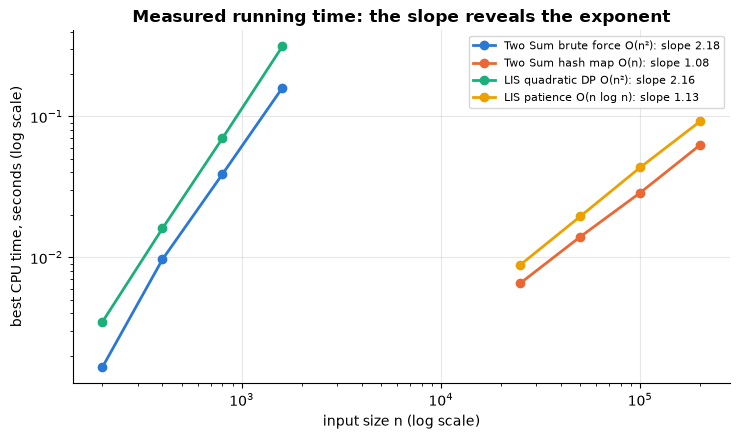

                algorithm  n first  n last  ms first  ms last  log-log slope
Two Sum brute force O(n²)      200    1600      1.67   159.53           2.18
    Two Sum hash map O(n)    25000  200000      6.55    62.69           1.08
   LIS quadratic DP O(n²)      200    1600      3.49   313.95           2.16
  LIS patience O(n log n)    25000  200000      8.83    92.19           1.13


In [50]:
def measure(fn, make_input, ns, repeat=7):
    """Best-of-`repeat` CPU time for fn(*make_input(n)) at each n, plus the fitted log-log slope."""
    times = []
    for n in ns:
        args = make_input(n)
        # timer=time.process_time counts only the CPU time of THIS process, so other programs
        # running on the machine at the same time distort the measurement much less than wall time
        times.append(min(timeit.repeat(lambda: fn(*args), number=1, repeat=repeat, timer=time.process_time)))
    slope = np.polyfit(np.log(ns), np.log(times), 1)[0]
    return np.array(times), slope

rng_t = random.Random(0)
experiments = {
    "Two Sum brute force O(n²)": (two_sum_brute, lambda n: (list(range(n)), -1), [200, 400, 800, 1600]),
    "Two Sum hash map O(n)": (two_sum, lambda n: (list(range(n)), -1), [25_000, 50_000, 100_000, 200_000]),
    "LIS quadratic DP O(n²)": (lis_quadratic, lambda n: ([rng_t.random() for _ in range(n)],), [200, 400, 800, 1600]),
    "LIS patience O(n log n)": (lis_length, lambda n: ([rng_t.random() for _ in range(n)],), [25_000, 50_000, 100_000, 200_000]),
}
rows, fig, ax = [], *plt.subplots(figsize=(7.5, 4.5))
for name, (fn, make, ns) in experiments.items():
    times, slope = measure(fn, make, ns)
    rows.append((name, ns[0], ns[-1], times[0] * 1e3, times[-1] * 1e3, slope))
    ax.loglog(ns, times, "o-", label=f"{name}: slope {slope:.2f}")
ax.set_xlabel("input size n (log scale)"); ax.set_ylabel("best CPU time, seconds (log scale)")
ax.set_title("Measured running time: the slope reveals the exponent")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

timing = pd.DataFrame(rows, columns=["algorithm", "n first", "n last", "ms first", "ms last", "log-log slope"]).round(2)
print(timing.to_string(index=False))
quad = timing["log-log slope"][timing.algorithm.str.contains("O\\(n²\\)")]
lin = timing["log-log slope"][~timing.algorithm.str.contains("O\\(n²\\)")]
assert quad.between(1.5, 2.7).all() and lin.between(0.6, 1.6).all(), "slopes outside the expected ranges"
assert quad.min() > lin.max() + 0.4                    # the quadratic algorithms clearly grow faster

**What just happened?** The two quadratic algorithms have slopes close to 2 and the two near-linear ones have slopes close to 1 (the table prints the exact fitted values; they vary a little from run to run). The $O(n \log n)$ patience algorithm's slope is also close to 1: over an 8× range of $n$, the extra $\log n$ factor grows only from about 14.6 to 17.6 (in bits), which is hard to see under timing noise. Notice also the **constant factors**: at $n = 1600$ the quadratic algorithms already take longer than the fast ones take at $n = 200{,}000$.

⚠️ **Common mistake:** timing a single run at a single size. One number tells you nothing about growth, and the first call often includes warm-up costs. Use several sizes, several repeats, and take the minimum.

🎓 **Interview tip:** you can use the "doubling ratio" mentally: if you are told $n$ grew 10× and the job got 100× slower, the code is quadratic.

## 19. Python interview idioms (and traps)

> 💬 **In plain English:** the Python standard-library tools that make interview code short, and the traps that cost points.

Python lets you write interview solutions in half the lines of Java or C++, **if** you know the standard library. These are the tools used throughout this workbook.

| Need | Tool | Cost |
|---|---|---|
| count things | `Counter(xs)`, `.most_common(k)` | $O(n)$; most_common($k$) uses a heap |
| dict with a default value | `defaultdict(list)` / `defaultdict(int)` | $O(1)$ per access |
| queue / BFS / sliding window | `deque`: `append`, `popleft` | $O(1)$ at both ends |
| min-heap | `heapq.heappush`, `heappop`, `heapify`, `heapreplace`, `nlargest` | $O(\log n)$; heapify $O(n)$ |
| max-heap | push `-x`, or tuples `(-priority, tiebreak, item)` | |
| sorted-list search | `bisect_left`, `bisect_right`, `insort` | $O(\log n)$ search; insort $O(n)$ (list shift) |
| memoised recursion | `@functools.cache` (or `lru_cache(maxsize=None)`) | stores every argument tuple |
| combinatorics | `itertools.combinations`, `permutations`, `product`, `accumulate`, `pairwise` | lazy iterators |
| infinity | `math.inf` | |

In [51]:
# 1) heapq is a MIN-heap. Max-heap by negation; break ties with a counter so items are never compared.
tasks = [("write tests", 2), ("fix bug", 5), ("lunch", 5), ("deploy", 3)]
heap, tie = [], itertools.count()
for name, priority in tasks:
    heapq.heappush(heap, (-priority, next(tie), name))      # highest priority first, FIFO among equals
print("max-heap order:", [heapq.heappop(heap)[2] for _ in range(len(tasks))])
print("3 largest:", heapq.nlargest(3, [5, 1, 8, 3, 9, 2]), "| 2 smallest:", heapq.nsmallest(2, [5, 1, 8, 3]))

# 2) bisect: count values in a range of a sorted list in O(log n)
scores = sorted([12, 45, 45, 67, 70, 88, 91])
print("scores in [45, 80]:", bisect.bisect_right(scores, 80) - bisect.bisect_left(scores, 45))

# 3) deque vs list for queues: list.pop(0) shifts every element (O(n))
big = list(range(20_000))
t_list = min(timeit.repeat(lambda: [x.pop(0) for x in [big.copy()] for _ in range(20_000)], number=1, repeat=3))
t_deque = min(timeit.repeat(lambda: [x.popleft() for x in [deque(big)] for _ in range(20_000)], number=1, repeat=3))
print(f"draining 20,000 items: list.pop(0) {t_list*1e3:.1f} ms vs deque.popleft {t_deque*1e3:.1f} ms")

# 4) functools.cache turns exponential recursion into DP
calls = Counter()
def fib_slow(n):
    calls["slow"] += 1
    return n if n < 2 else fib_slow(n - 1) + fib_slow(n - 2)
@functools.cache
def fib_fast(n):
    calls["fast"] += 1
    return n if n < 2 else fib_fast(n - 1) + fib_fast(n - 2)
assert fib_slow(25) == fib_fast(25) == 75025
print("calls to compute fib(25): plain recursion", calls["slow"], "| memoised", calls["fast"])

max-heap order: ['fix bug', 'lunch', 'deploy', 'write tests']
3 largest: [9, 8, 5] | 2 smallest: [1, 3]
scores in [45, 80]: 4


draining 20,000 items: list.pop(0) 67.1 ms vs deque.popleft 1.8 ms


calls to compute fib(25): plain recursion 242785 | memoised 26


In [52]:
# 5) Recursion limit: Python's default is about 1000 frames, so deep recursive DFS crashes.
print("recursion limit:", sys.getrecursionlimit())
def depth_recursive(n):
    return 0 if n == 0 else 1 + depth_recursive(n - 1)
try:
    depth_recursive(5_000)
except RecursionError as e:
    print("RecursionError caught:", str(e)[:45], "...")
def depth_iterative(n):                     # the fix: an explicit loop/stack
    d = 0
    while n:
        n, d = n - 1, d + 1
    return d
print("iterative version handles 5,000:", depth_iterative(5_000))
# (sys.setrecursionlimit(10**6) also works for moderate depths, but can crash the interpreter with a C stack overflow.)

# 6) Classic traps
grid_bad = [[0] * 3] * 2                    # TRAP: both rows are the SAME list object
grid_bad[0][0] = 1
grid_good = [[0] * 3 for _ in range(2)]     # one new list per row
grid_good[0][0] = 1
print("aliasing trap:", grid_bad, "vs correct:", grid_good)

def append_bad(x, acc=[]):                  # TRAP: the default list is created once and shared
    acc.append(x); return acc
append_bad(1)
print("mutable default trap: second call returns", append_bad(2))

# 7) Sorting is stable and takes a key: sort by score desc, then name asc
people = [("ana", 90), ("bo", 85), ("cy", 90), ("di", 85)]
print("sorted:", sorted(people, key=lambda p: (-p[1], p[0])))

recursion limit: 1000
RecursionError caught: maximum recursion depth exceeded ...
iterative version handles 5,000: 5000
aliasing trap: [[1, 0, 0], [1, 0, 0]] vs correct: [[1, 0, 0], [0, 0, 0]]
mutable default trap: second call returns [1, 2]
sorted: [('ana', 90), ('cy', 90), ('bo', 85), ('di', 85)]


**What just happened?** Popping from the front of a Python list is $O(n)$ because every remaining element shifts left; `deque.popleft` is $O(1)$, and the timing shows the gap (the exact milliseconds are printed above). Memoisation reduced 242,785 calls to 26. The recursion-limit and aliasing traps produce **wrong answers or crashes that only appear on large inputs**, exactly the inputs an interviewer's hidden tests use.

🎓 **Interview tip:** say "I'll use `heapq`, which is a min-heap, so I'll push negated priorities" out loud. It shows you know the tool's contract.

## 20. ML-flavoured coding questions

> 💬 **In plain English:** six questions that ML/AI interviews actually ask, each implemented from scratch and checked against a library.

ML and AI engineer interviews often replace one algorithm puzzle with "implement this ML building block from scratch in NumPy". These six come up again and again. Each is checked against a library or a brute-force definition.

### 20.1 k-means (Lloyd's algorithm with k-means++ initialisation)

**Definition.** Given points $x_1..x_n$ and $k$, **k-means** looks for centres $\mu_1..\mu_k$ minimising the **inertia** $\sum_i \min_j \lVert x_i - \mu_j \rVert^2$. **Lloyd's algorithm** alternates (1) assign each point to its nearest centre, (2) move each centre to the mean of its points. Each step cannot increase inertia, so it converges, but only to a **local** optimum; hence several restarts and the **k-means++** seeding (pick each new centre with probability ∝ squared distance to the nearest existing one), which is $O(\log k)$-competitive in expectation (Arthur & Vassilvitskii, 2007).

In [53]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

def kmeans(X, k, n_init=10, max_iter=100, seed=0):
    """Lloyd's algorithm with k-means++ seeding and restarts. Returns (inertia, centres, labels)."""
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centres = [X[rng.integers(len(X))]]                         # k-means++: first centre uniformly
        for _ in range(1, k):
            d2 = ((X[:, None, :] - np.array(centres)[None]) ** 2).sum(-1).min(1)   # squared distance to nearest centre
            centres.append(X[rng.choice(len(X), p=d2 / d2.sum())])   # far points are more likely
        C = np.array(centres)
        for _ in range(max_iter):
            labels = ((X[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)            # assignment step
            new_C = np.array([X[labels == j].mean(0) if np.any(labels == j) else C[j] for j in range(k)])  # update step
            if np.allclose(new_C, C):
                break
            C = new_C
        labels = ((X[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - C[labels]) ** 2).sum()
        if best is None or inertia < best[0]:
            best = (inertia, C, labels)
    return best

X, y_true = make_blobs(n_samples=400, centers=4, cluster_std=1.2, random_state=0)
ours_inertia, ours_C, ours_labels = kmeans(X, 4)
sk = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
print(f"inertia: ours {ours_inertia:.2f} | scikit-learn {sk.inertia_:.2f}")
print(f"agreement of the two clusterings (adjusted Rand index): {adjusted_rand_score(sk.labels_, ours_labels):.3f}")
assert ours_inertia <= sk.inertia_ * 1.01

inertia: ours 920.08 | scikit-learn 920.08
agreement of the two clusterings (adjusted Rand index): 1.000


**What just happened?** Our 25-line k-means reaches the same inertia as scikit-learn (to within 1%, checked by the `assert`) and the same partition (adjusted Rand index printed above; 1.0 means identical up to renaming the clusters). **Complexity:** $O(n k d)$ per iteration for $n$ points in $d$ dimensions; memory $O(nk)$ for the distance matrix used here (chunk it for large $n$).

### 20.2 ROC AUC from scratch

**Definition.** The **AUC** is the probability that a randomly chosen positive gets a higher score than a randomly chosen negative (ties count ½). That equals the normalised **Mann–Whitney U** statistic, computable from **ranks** in $O(n \log n)$ instead of comparing all $n_+ n_-$ pairs:
$$\text{AUC} = \frac{\sum_{i \in +} \text{rank}_i - n_+(n_+ + 1)/2}{n_+ n_-},$$
with tied scores given their **average** rank.

In [54]:
from sklearn.metrics import roc_auc_score

def average_ranks(s):
    """1-based ranks with ties replaced by their average rank (like scipy.stats.rankdata)."""
    order = np.argsort(s, kind="mergesort")
    ranks = np.empty(len(s))
    sorted_s = np.asarray(s)[order]
    i = 0
    while i < len(s):
        j = i
        while j + 1 < len(s) and sorted_s[j + 1] == sorted_s[i]:
            j += 1                                    # [i, j] is a block of ties
        ranks[order[i:j + 1]] = (i + j) / 2 + 1       # average of ranks i+1 .. j+1
        i = j + 1
    return ranks

def roc_auc(y, s):
    y, r = np.asarray(y), average_ranks(s)
    n_pos, n_neg = y.sum(), len(y) - y.sum()
    return (r[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def roc_auc_pairs(y, s):                               # definition: compare every (positive, negative) pair
    pos, neg = [b for a, b in zip(y, s) if a == 1], [b for a, b in zip(y, s) if a == 0]
    return sum((p > q) + 0.5 * (p == q) for p in pos for q in neg) / (len(pos) * len(neg))

rng = np.random.default_rng(0)
for trial in range(200):
    n = int(rng.integers(2, 40))
    y = rng.integers(0, 2, n)
    if y.min() == y.max():
        continue                                       # AUC needs both classes
    s = np.round(rng.random(n) + 0.3 * y, 1)           # rounding creates ties on purpose
    assert math.isclose(roc_auc(y, s), roc_auc_score(y, s)) and math.isclose(roc_auc(y, s), roc_auc_pairs(y, s))
print("AUC example:", roc_auc([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), "(sklearn:", roc_auc_score([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), ")")
report("ROC AUC (rank formula)", 1, 200)

AUC example: 0.75 (sklearn: 0.75 )
✅ ROC AUC (rank formula): 1 fixed + 200 random tests passed


**What just happened?** The rank formula matched both scikit-learn and the pairwise definition on 200 random cases with ties. In the example, 3 of the 4 positive–negative pairs are ordered correctly, so AUC = 0.75. **Complexity:** $O(n \log n)$ (the sort) vs $O(n_+ n_-)$ for the pairwise definition.

### 20.3 IoU and non-maximum suppression (object detection)

**Definitions.** For boxes $(x_1, y_1, x_2, y_2)$, **intersection over union** is $\text{IoU} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$. A detector proposes many overlapping boxes for one object; **greedy NMS** keeps the highest-scoring box, deletes every remaining box with IoU above a threshold with it, and repeats.

In [55]:
def iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))       # width of the overlap (0 if none)
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def iou_pixels(a, b):                                       # brute force on integer boxes: count unit squares
    A = {(x, y) for x in range(a[0], a[2]) for y in range(a[1], a[3])}
    B = {(x, y) for x in range(b[0], b[2]) for y in range(b[1], b[3])}
    return len(A & B) / len(A | B) if A | B else 0.0

def nms(boxes, scores, thr=0.5):
    order = sorted(range(len(boxes)), key=lambda i: -scores[i])     # best first
    keep = []
    while order:
        i = order.pop(0)
        keep.append(i)
        order = [j for j in order if iou(boxes[i], boxes[j]) <= thr]  # drop boxes that overlap i too much
    return keep

rng = random.Random(0)
rand_box = lambda: (lambda x, y: (x, y, x + rng.randint(1, 6), y + rng.randint(1, 6)))(rng.randint(0, 8), rng.randint(0, 8))
for _ in range(500):
    a, b = rand_box(), rand_box()
    assert math.isclose(iou(a, b), iou_pixels(a, b))
for _ in range(200):                                       # NMS properties instead of one exact answer
    boxes = [rand_box() for _ in range(rng.randint(1, 10))]
    scores = [rng.random() for _ in boxes]
    keep = nms(boxes, scores, 0.4)
    assert all(iou(boxes[i], boxes[j]) <= 0.4 for i, j in itertools.combinations(keep, 2))
    assert all(any(iou(boxes[i], boxes[j]) > 0.4 and scores[i] >= scores[j] for i in keep)
               for j in range(len(boxes)) if j not in keep)
dets = [(10, 10, 50, 50), (12, 12, 52, 52), (100, 100, 140, 150), (11, 9, 49, 51)]
print("IoU of the first two boxes:", round(iou(dets[0], dets[1]), 3), "| kept by NMS:", nms(dets, [0.9, 0.8, 0.7, 0.95], 0.5))
try:
    import torch, torchvision                              # optional cross-check
    tv = torchvision.ops.nms(torch.tensor(dets, dtype=torch.float32), torch.tensor([0.9, 0.8, 0.7, 0.95]), 0.5).tolist()
    print("torchvision.ops.nms agrees:", tv == nms(dets, [0.9, 0.8, 0.7, 0.95], 0.5))
except Exception:
    print("torchvision not installed: skipping the optional cross-check")
report("IoU + NMS", 2, 700)

IoU of the first two boxes: 0.822 | kept by NMS: [3, 2]


torchvision.ops.nms agrees: True
✅ IoU + NMS: 2 fixed + 700 random tests passed


**What just happened?** IoU matched a pixel-counting brute force on 500 random integer boxes. For NMS we tested the two **properties** that define a correct result: no two kept boxes overlap above the threshold, and every removed box overlaps a kept box with a higher (or equal) score. In the 4-box example, box 3 (score 0.95) suppresses boxes 0 and 1, and the far-away box 2 survives. **Complexity:** greedy NMS is $O(n^2)$ IoU computations in the worst case; libraries vectorise it on the GPU.

### 20.4 Sampling the next token: temperature, top-k and top-p

**Definitions.** An LLM outputs **logits** $z$ over the vocabulary. **Temperature** $T$ rescales them: $p_i \propto e^{z_i / T}$ ($T \to 0$ = greedy, large $T$ = more random). **Top-k** keeps only the $k$ most probable tokens; **top-p (nucleus)** keeps the smallest set of most-probable tokens whose total probability is at least $p$ (Holtzman et al., 2020). After filtering, the kept probabilities are renormalised.

In [56]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())                    # subtract the max: avoids overflow, same result
    return e / e.sum()

def filtered_probs(logits, temperature=1.0, top_k=None, top_p=None):
    p = softmax(np.asarray(logits, dtype=float) / temperature)
    order = np.argsort(-p, kind="stable")      # most probable first
    keep = np.ones(len(p), dtype=bool)
    if top_k is not None:
        keep[order[top_k:]] = False
    if top_p is not None:
        cum = np.cumsum(p[order])
        cutoff = np.searchsorted(cum, top_p) + 1        # smallest prefix with total >= top_p
        keep[order[cutoff:]] = False
    q = np.where(keep, p, 0.0)
    return q / q.sum()

def sample_token(logits, rng, **kw):
    q = filtered_probs(logits, **kw)
    return rng.choice(len(q), p=q)

logits = [2.0, 1.0, 0.5, 0.1, -1.0]
table = pd.DataFrame({
    "T=1": filtered_probs(logits), "T=0.5": filtered_probs(logits, temperature=0.5),
    "T=2": filtered_probs(logits, temperature=2.0), "top_k=2": filtered_probs(logits, top_k=2),
    "top_p=0.8": filtered_probs(logits, top_p=0.8)}, index=[f"token {i}" for i in range(5)]).round(3)
print(table)

rng = np.random.default_rng(0)
draws = np.array([sample_token(logits, rng, top_p=0.8) for _ in range(20_000)])
freq = np.bincount(draws, minlength=5) / len(draws)
assert set(np.unique(draws)) <= set(np.flatnonzero(table["top_p=0.8"].values > 0))   # only allowed tokens
assert np.abs(freq - filtered_probs(logits, top_p=0.8)).max() < 0.015                # right frequencies
print("empirical frequencies (top_p=0.8, 20,000 draws):", freq.round(3))

           T=1  T=0.5    T=2  top_k=2  top_p=0.8
token 0  0.559  0.826  0.372    0.731      0.629
token 1  0.205  0.112  0.226    0.269      0.231
token 2  0.125  0.041  0.176    0.000      0.140
token 3  0.084  0.018  0.144    0.000      0.000
token 4  0.028  0.002  0.083    0.000      0.000


empirical frequencies (top_p=0.8, 20,000 draws): [0.624 0.238 0.138 0.    0.   ]


**What just happened?** Lower temperature sharpens the distribution (token 0 gets more mass), higher temperature flattens it. With these logits, `top_p=0.8` keeps 3 tokens (their cumulative probability first reaches 0.8 at the third one), and `top_k=2` keeps 2. The sampler only ever produced allowed tokens, at the expected frequencies. **Complexity:** $O(V \log V)$ per step for the sort over a vocabulary of size $V$ (production code uses partial sorts / `torch.topk`).

### 20.5 A tiny BPE tokenizer

**Definition.** **Byte-pair encoding** (Sennrich et al., 2016; used by the GPT family at the byte level) starts from characters and repeatedly **merges the most frequent adjacent pair** of symbols into a new symbol. Encoding applies the learned merges in the order they were learned.

In [57]:
PRETOKEN = re.compile(r"\s+|\w+|[^\w\s]+")      # whitespace runs, word runs, punctuation runs: covers every character

def merge_pair(symbols, pair):
    out, i = [], 0
    while i < len(symbols):
        if i + 1 < len(symbols) and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1]); i += 2
        else:
            out.append(symbols[i]); i += 1
    return tuple(out)

def train_bpe(text, num_merges):
    vocab = Counter(tuple(chunk) for chunk in PRETOKEN.findall(text))   # chunk (as chars) -> frequency
    merges = []
    for _ in range(num_merges):
        pairs = Counter()
        for sym, f in vocab.items():
            for a, b in zip(sym, sym[1:]):
                pairs[(a, b)] += f
        if not pairs:
            break
        best = min(pairs, key=lambda p: (-pairs[p], p))     # most frequent; ties broken alphabetically
        merges.append(best)
        vocab = Counter({merge_pair(sym, best): f for sym, f in vocab.items()})
    return merges

def bpe_encode(text, merges):
    rank = {pair: i for i, pair in enumerate(merges)}
    tokens = []
    for chunk in PRETOKEN.findall(text):
        sym = tuple(chunk)
        while len(sym) > 1:                                  # apply the earliest-learned merge available
            pair = min(zip(sym, sym[1:]), key=lambda p: rank.get(p, math.inf))
            if pair not in rank:
                break
            sym = merge_pair(sym, pair)
        tokens.extend(sym)
    return tokens

corpus = ("the model learns the lower layers first. the lowest loss wins. "
          "newer models learn faster than older models; the newest model is the best model. ") * 3
merges = train_bpe(corpus, 30)
print("first 8 merges:", ["".join(m) for m in merges[:8]])
toks = bpe_encode("the newest models learn", merges)
print("tokens:", toks)
rng = random.Random(0)
for _ in range(300):                                          # round trip on random text, including unseen characters
    s = "".join(rng.choice("the model, lowest! zq\n") for _ in range(rng.randint(0, 30)))
    assert "".join(bpe_encode(s, merges)) == s
n_chars, n_toks = len(corpus), len(bpe_encode(corpus, merges))
print(f"corpus: {n_chars} characters -> {n_toks} tokens ({n_chars / n_toks:.2f} chars per token)")
report("BPE tokenizer round trip", 1, 300)

first 8 merges: ['de', 'th', 'del', 'mo', 'model', 'st', 'the', 'er']
tokens: ['the', ' ', 'new', 'est', ' ', 'models', ' ', 'learn']
corpus: 432 characters -> 207 tokens (2.09 chars per token)
✅ BPE tokenizer round trip: 1 fixed + 300 random tests passed


**What just happened?** The first merges glue together the most frequent pairs in this little corpus (printed above), and frequent words such as `the` and `model` quickly become single tokens. Decoding is just concatenation, and it reproduced 300 random strings exactly, even with characters never seen in training. The compression ratio is printed above. **Complexity:** training is $O(M \cdot N)$ for $M$ merges over a corpus of $N$ symbols in this simple version (real implementations update pair counts incrementally); see [`08_LLM/00_start_here_how_llms_work`](../../08_LLM/00_start_here_how_llms_work.ipynb) for where tokenizers sit in an LLM.

### 20.6 An LRU cache for embeddings

**Definition.** A **least-recently-used (LRU) cache** keeps at most `capacity` items; on overflow it evicts the item unused for the longest time. Both `get` and `put` must be $O(1)$: a **hash map** finds the node, and a **doubly linked list** keeps recency order so a node can be moved or removed in $O(1)$.

In [58]:
class _Node:
    __slots__ = ("key", "val", "prev", "next")
    def __init__(self, key=None, val=None):
        self.key, self.val, self.prev, self.next = key, val, None, None

class LRUCache:
    """dict + doubly linked list; most recent right after `head`, least recent right before `tail`."""
    def __init__(self, capacity):
        self.cap, self.map = capacity, {}
        self.head, self.tail = _Node(), _Node()                # sentinels: no edge cases at the ends
        self.head.next, self.tail.prev = self.tail, self.head
        self.hits = self.misses = 0
    def _unlink(self, node):
        node.prev.next, node.next.prev = node.next, node.prev
    def _push_front(self, node):
        node.prev, node.next = self.head, self.head.next
        self.head.next.prev = node
        self.head.next = node
    def get(self, key):
        node = self.map.get(key)
        if node is None:
            self.misses += 1
            return None
        self.hits += 1
        self._unlink(node); self._push_front(node)              # mark as most recently used
        return node.val
    def put(self, key, val):
        if key in self.map:
            self._unlink(self.map[key])
        node = self.map[key] = _Node(key, val)
        self._push_front(node)
        if len(self.map) > self.cap:
            lru = self.tail.prev                                # least recently used
            self._unlink(lru); del self.map[lru.key]

class LRUOracle:                                                # slow but obvious: a list in recency order
    def __init__(self, capacity):
        self.cap, self.items = capacity, []
    def get(self, key):
        for i, (k, v) in enumerate(self.items):
            if k == key:
                self.items.append(self.items.pop(i)); return v
        return None
    def put(self, key, val):
        self.items = [(k, v) for k, v in self.items if k != key] + [(key, val)]
        if len(self.items) > self.cap:
            self.items.pop(0)

rng = random.Random(0)
for trial in range(200):
    cap = rng.randint(1, 4)
    a, b = LRUCache(cap), LRUOracle(cap)
    for _ in range(40):
        k = rng.randint(0, 6)
        if rng.random() < 0.5:
            assert a.get(k) == b.get(k)
        else:
            v = rng.random(); a.put(k, v); b.put(k, v)
report("LRU cache vs list oracle", 0, 200)

# Use it as an embedding cache: queries follow a Zipf-like law (a few are very popular)
embed_calls = Counter()
def fake_embed(text):                                           # stand-in for an expensive embedding model
    embed_calls["n"] += 1
    return np.random.default_rng(zlib.crc32(text.encode())).standard_normal(8)   # deterministic fake vector
queries = [f"q{int(z)}" for z in np.random.default_rng(1).zipf(1.3, 5_000) if z < 10_000]
rows = []
for cap in [10, 50, 200, 1000]:
    cache, embed_calls["n"] = LRUCache(cap), 0
    for q in queries:
        if cache.get(q) is None:
            cache.put(q, fake_embed(q))
    rows.append((cap, cache.hits / len(queries), embed_calls["n"]))
print(pd.DataFrame(rows, columns=["capacity", "hit rate", "embedding calls"]).round(3).to_string(index=False))

✅ LRU cache vs list oracle: 0 fixed + 200 random tests passed


 capacity  hit rate  embedding calls
       10     0.469             2513
       50     0.706             1393
      200     0.819              858
     1000     0.860              663


**What just happened?** The $O(1)$ cache behaved exactly like the slow list-based oracle on 200 random operation sequences. On a Zipf-like query stream, even a small cache answers a large share of requests without calling the "model", and the hit rate grows with capacity (table above): that is why embedding and LLM-response caches pay off. In Python you would normally write `functools.lru_cache` or use `OrderedDict.move_to_end`, but interviews ask for the linked-list version to see if you know **why** both operations are $O(1)$.

## 21. A 4-week practice plan and self-assessment

> 💬 **In plain English:** a realistic study plan and a checklist to see which patterns you really own.

**Rules that make practice work** (from cognitive-science research on learning: spacing, retrieval and interleaving):
- **Time-box** each problem: 25 minutes to solve, then read the hint, then the solution. Re-solve it from scratch **3 days later**.
- **Say it aloud** or write the 7 steps as comments before coding.
- **Mix patterns** after week 2, so you practise *recognising* the pattern, not just applying the one you just read about.
- Keep an **error log**: problem, what went wrong (wrong pattern? off-by-one? missed edge case?), and the fix.

| Week | Days 1–2 | Days 3–4 | Days 5–6 | Day 7 |
|---|---|---|---|---|
| 1 | §1 method, two pointers (P1–P3) | sliding window (P4–P6), prefix sums (P7–P8) | hashing (P9–P11), stacks (P12–P14) | mock: 2 random problems from week 1, 45 min |
| 2 | binary search (P15–P18) | heaps (P19–P22) | intervals (P23–P25), grids (P26–P28) | mock + redo every problem in the error log |
| 3 | topological sort, union-find (P29–P31) | DP 1-D/2-D (P32–P34) | knapsack, LIS, edit distance, LCS (P35–P38) | mock with DP + one graph problem |
| 4 | backtracking (P39–P42) | tries, bits (P43–P45), §19 idioms | §20 ML questions (all 6) | two full mocks (45 min each), practice problems below |

**Self-assessment.** Copy this table into your notes and fill it in honestly at the end of each week. Aim for ✅ in all three columns before an interview.

| Pattern | I recognise it from the wording | I can code the template in < 10 min without notes | I can state and justify its complexity |
|---|---|---|---|
| Two pointers | | | |
| Sliding window | | | |
| Prefix sums | | | |
| Hashing | | | |
| Monotonic stack | | | |
| Binary search on the answer | | | |
| Heap / top-k | | | |
| Intervals | | | |
| BFS / DFS on grids | | | |
| Topological sort | | | |
| Union-find | | | |
| Dynamic programming | | | |
| Backtracking | | | |
| Trie | | | |
| Bit manipulation | | | |
| ML building blocks (§20) | | | |

In [59]:
# Problem numbers per pattern, used in the schedule above (generated, so the plan stays in sync with the workbook)
plan, start = [], 1
for heading, count in [(h, c) for h, c in PATTERN_COUNTS]:
    plan.append((heading, f"P{start}–P{start + count - 1}" if count > 1 else f"P{start}"))
    start += count
print(pd.DataFrame(plan, columns=["pattern", "problems"]).to_string(index=False))

                                                     pattern problems
                                                Two pointers    P1–P3
                                              Sliding window    P4–P6
                                                 Prefix sums    P7–P8
                                                     Hashing   P9–P11
                                   Stack and monotonic stack  P12–P14
               Binary search (on an index and on the answer)  P15–P18
                                              Heap and top-k  P19–P22
                                                   Intervals  P23–P25
                                          BFS / DFS on grids  P26–P28
                                            Topological sort      P29
                             Union-find (disjoint set union)  P30–P31
Dynamic programming (1-D, 2-D, knapsack, LIS, edit distance)  P32–P38
                                                Backtracking  P39–P42
                    

## 🔗 How this connects to modern AI

| Pattern in this workbook | Where it runs in real AI systems |
|---|---|
| Heap / top-k (P19–P22) | the final step of vector search in **RAG**: keep the k nearest chunks ([`22_ML_System_Design/05_vector_databases`](../../22_ML_System_Design/05_vector_databases.ipynb)); top-k sampling in LLM decoding (§20.4) |
| Sliding window | streaming feature computation (rolling averages), **sliding-window attention** in long-context LLMs |
| Prefix sums | the parallel **scan** that powers state-space models such as Mamba, and `cumsum` for top-p sampling (next notebook) |
| Binary search on the answer | tuning a threshold to hit a target precision/recall, finding the largest batch size that fits in GPU memory |
| Topological sort | ordering operations in the **autograd** graph of PyTorch, scheduling steps in data/ML pipelines (Airflow DAGs) |
| Union-find | clustering near-duplicate documents for **training-data deduplication** |
| Edit distance (P37) | **word error rate** for speech recognition; fuzzy matching of entity names |
| Trie (P43) | tokenizer vocabularies and **constrained decoding** (only allow tokens that keep the output valid JSON) |
| BPE, LRU, AUC, NMS (§20) | tokenizers, embedding and response caches, model evaluation, object detection |

Related notebooks: [`dsa/12` DSA in AI systems](../dsa/12_industry_dsa_in_ai_systems.ipynb), [`23_Software_Engineering/03` testing AI code](../../23_Software_Engineering/03_testing_ai_code.ipynb) (property-based testing generalises the random-oracle idea used here), and [`08_LLM/13_inference_optimization`](../../08_LLM/13_inference_optimization.ipynb).

## Recap

- Use the **7-step method**: clarify, examples, brute force, optimise, code, test, analyse. The brute force is not wasted: it becomes your **test oracle**.
- About **15 patterns** cover most interview problems. Learn the **signal** in the wording that points to each one (section 2).
- Test fast code against slow code on **hundreds of random small inputs**; it finds the edge cases that hand-written tests miss.
- Check complexity claims **empirically** with a log-log plot: the slope is the exponent.
- Know the Python toolbox (`Counter`, `defaultdict`, `deque`, `heapq`, `bisect`, `functools.cache`, `itertools`) and its traps (recursion limit, list aliasing, mutable defaults, `list.pop(0)`).
- ML interviews ask for building blocks from scratch: k-means, AUC, IoU/NMS, sampling, tokenizers, caches.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested against a brute force when this notebook was built.

**1. (Easy, conceptual)** Name the pattern you would try first: (a) longest substring with at most 2 distinct characters; (b) the k points closest to the origin; (c) the minimum number of days until you can make `m` bouquets, if flower `i` blooms on day `d[i]`; (d) whether a set of course prerequisites contains a cycle; (e) the number of subarrays whose sum is divisible by `k`.

<details><summary>Show solution</summary>

(a) **Sliding window**: "at most 2 distinct" is monotone (shrinking keeps it true). (b) **Heap** of size k (or quickselect): $O(n \log k)$. (c) **Binary search on the answer**: if you can make `m` bouquets by day `t`, you can by any later day. (d) **Topological sort** (Kahn's: leftover nodes mean a cycle) or DFS with colours. (e) **Prefix sums + hashing**: count prefix remainders `P mod k`; two equal remainders bound a divisible subarray.

</details>

**2. (Easy, coding)** *Trapping rain water* (LeetCode #42): given bar heights, how much water is trapped after rain? `[0,1,0,2,1,0,1,3,2,1,2,1]` → `6`. Do it in $O(n)$ time and $O(1)$ space.

<details><summary>Show solution</summary>

The water above bar `k` is `min(max left, max right) - h[k]`. Two pointers: whichever side has the smaller current bar is limited by **its own** running maximum, so it can be settled immediately.

```python
def trap_rain(h):
    """Water trapped between bars, two pointers, O(n) time, O(1) space."""
    i, j = 0, len(h) - 1
    left_max = right_max = water = 0
    while i < j:
        if h[i] < h[j]:                    # the left side is the bottleneck
            left_max = max(left_max, h[i])
            water += left_max - h[i]
            i += 1
        else:
            right_max = max(right_max, h[j])
            water += right_max - h[j]
            j -= 1
    return water
```
Tested against the $O(n^2)$ definition on 500 random inputs.

</details>

**3. (Medium, conceptual)** Problem 4 (minimum size subarray sum) uses a sliding window. Give a counterexample showing the window breaks if negative numbers are allowed, and name an $O(n)$ fix.

<details><summary>Show solution</summary>

`nums = [5, -10, 6]`, `target = 6`. The window grows to `[5]` (sum 5), then `[5, -10]` (sum −5), then `[5, -10, 6]` (sum 1); the sum never reaches 6 while `left = 0`, so the window never shrinks and the single element `[6]` (length 1) is missed. Shrinking is no longer "safe" because removing an element can **increase** the sum. Fix: prefix sums $P$ and a **monotonic deque** of indices with increasing $P$; for each $r$, pop from the front while $P[r] - P[\text{front}] \ge$ target (recording lengths), and pop from the back while $P[\text{back}] \ge P[r]$. $O(n)$ (LeetCode #862).

</details>

**4. (Medium, coding)** *Word break* (LeetCode #139): can `s` be split into words from a dictionary? `"leetcode", ["leet", "code"]` → `True`.

<details><summary>Show solution</summary>

```python
def word_break(s, words):
    """dp[i] = True if s[:i] can be split into dictionary words. O(n * L) checks, L = longest word."""
    words = set(words)
    L = max(map(len, words), default=0)
    dp = [True] + [False] * len(s)
    for i in range(1, len(s) + 1):
        dp[i] = any(dp[j] and s[j:i] in words for j in range(max(0, i - L), i))
    return dp[-1]
```
$O(n L)$ substring checks (each of cost $O(L)$), where $L$ is the longest word. Tested against a memoised recursive brute force on 500 random cases.

</details>

**5. (Medium, coding)** *Alien dictionary* (LeetCode #269): words are sorted in an unknown alphabet. Return one possible letter order, or `""` if the input is inconsistent.

<details><summary>Show solution</summary>

Each adjacent pair of words gives at most one constraint (their first differing letters). Build the graph and topologically sort it; a cycle or a word followed by its own prefix means "invalid".

```python
from collections import defaultdict, deque

def alien_order(words):
    """Letter order of an alien alphabet from a sorted word list ('' if inconsistent). Kahn's algorithm."""
    letters = {ch for w in words for ch in w}
    adj, indeg = defaultdict(set), {ch: 0 for ch in letters}
    for a, b in zip(words, words[1:]):
        for x, y in zip(a, b):
            if x != y:                         # first difference gives one constraint x < y
                if y not in adj[x]:
                    adj[x].add(y); indeg[y] += 1
                break
        else:
            if len(a) > len(b):                # "abc" before "ab" is impossible
                return ""
    q = deque(sorted(ch for ch in letters if indeg[ch] == 0))
    order = []
    while q:
        ch = q.popleft(); order.append(ch)
        for nxt in sorted(adj[ch]):
            indeg[nxt] -= 1
            if indeg[nxt] == 0:
                q.append(nxt)
    return "".join(order) if len(order) == len(letters) else ""
```
Test: we generate words sorted by a random secret alphabet and check that sorting them with the returned order reproduces the input (500 random cases).

</details>

**6. (Hard, coding, ML)** Given `Q` query embeddings and `D` document embeddings, return the indices of the `k` most cosine-similar documents for every query, best first, **without** fully sorting each row.

<details><summary>Show solution</summary>

`np.argpartition` finds the unordered top $k$ in $O(D)$ per row; only those $k$ are then sorted.

```python
import numpy as np

def top_k_cosine(queries, docs, k):
    """Indices of the k most cosine-similar docs for every query, best first. O(Q*D*d + Q*D) with argpartition."""
    qn = queries / np.linalg.norm(queries, axis=1, keepdims=True)
    dn = docs / np.linalg.norm(docs, axis=1, keepdims=True)
    sims = qn @ dn.T                                          # (Q, D) cosine similarities
    part = np.argpartition(-sims, k - 1, axis=1)[:, :k]      # unordered top k per row, O(D) each
    order = np.argsort(-np.take_along_axis(sims, part, axis=1), axis=1)
    return np.take_along_axis(part, order, axis=1)
```
Checked against a full `argsort` on 50 random shapes (compared by similarity values, so ties are allowed).

</details>

**7. (Hard, conceptual)** An interviewer says: "Your autocomplete uses a trie. Why not a sorted list with `bisect`?" Compare the two for (a) memory, (b) prefix lookup, (c) inserting new words, (d) returning the first `k` completions.

<details><summary>Show solution</summary>

(a) A sorted list stores each word once; a trie stores one node per distinct prefix, often with dict overhead, so the list is usually **smaller** in Python. (b) Both are fast: bisect finds the first word $\ge$ prefix in $O(L \log n)$ (string comparisons cost up to $O(L)$); a trie walk is $O(L)$, independent of $n$. (c) Insertion into a sorted list is $O(n)$ (shifting); into a trie $O(L)$. (d) Sorted list: bisect, then read the next $k$ entries, $O(L \log n + kL)$, which is simple and cache-friendly. Trie: $O(L)$ + a DFS that stops after $k$ words. Conclusion: for a **static** dictionary a sorted list (or a compact trie / FST, as used in Lucene) is often best; for **frequent inserts** or per-prefix statistics (counts, top-scored completions stored per node) a trie wins.

</details>

## Further reading

- Cormen, Leiserson, Rivest & Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022): ch. 4 (divide and conquer), 6 (heapsort / heaps), 14 (dynamic programming), 15 (greedy), 19 (disjoint sets), 20 (elementary graph algorithms, BFS/DFS/topological sort).
- S. Skiena, *The Algorithm Design Manual* (3rd ed., 2020): part I, and the "war stories" for problem-solving process.
- A. Aziz, T.-H. Lee & A. Prakash, *Elements of Programming Interviews in Python* (2018); G. Laakmann McDowell, *Cracking the Coding Interview* (6th ed., 2015).
- D. Arthur & S. Vassilvitskii, "k-means++: the advantages of careful seeding", SODA 2007; Holtzman et al., "The Curious Case of Neural Text Degeneration" (top-p sampling), ICLR 2020; Sennrich, Haddow & Birch, "Neural Machine Translation of Rare Words with Subword Units" (BPE), ACL 2016.
- Free online: the [Tech Interview Handbook](https://www.techinterviewhandbook.org/) (study plans and the interview rubric) and [cp-algorithms](https://cp-algorithms.com/) (rigorous write-ups of every pattern).

## Next notebook
➡️ [10 · Parallel and external-memory algorithms](10_parallel_and_external_memory_algorithms.ipynb): work and span, Amdahl's and Gustafson's laws, the parallel prefix sum, external merge sort and ring all-reduce.

⬅️ Previous: [08 · Advanced data structures](08_advanced_data_structures.ipynb)